# CACIB calibration: S&P 500, EURO STOXX 50 and Call vs Call

# Model

The notebook uses directly the two-asset specification of Example 1.1. For
$i\in\{1,2\}$,

$$
\frac{dS_t^i}{S_t^i}=\sigma_i(t,Y_t^i)\,dB_t^i,
\qquad
d\langle B^1,B^2\rangle_t=\rho\,dt,
$$

$$
Y_t^i=Y_0^i+\nu_i\int_0^tK_i(t,s)\,dW_s^i,
\qquad
W_t^i=c_iB_t^i+\sqrt{1-c_i^2}\,B_t^{\perp,i},
$$

where $B^\perp$ is independent of $B$. The normalized volatility is

$$
\sigma_i(t,Y_t^i)
=G_0^i(t)\frac{Y_t^i}{\sqrt{\mathbb E[(Y_t^i)^2]}}.
$$

In matrix notation,

$$
\eta=\operatorname{diag}(\nu_1,\nu_2),\qquad
C=\operatorname{diag}(c_1,c_2),\qquad
\rho_B=\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix},
$$

$$
R_W=C^\top\rho_BC+I_2-\operatorname{diag}(C^\top C).
$$

With column-major vectorization,

$$
\Gamma=
\begin{pmatrix}
1&0\\
0&0\\
0&0\\
0&1
\end{pmatrix},
\qquad
Z_t=\begin{pmatrix}Y_t^1&0\\0&Y_t^2\end{pmatrix}.
$$

The variance-swap term structures determine the two deterministic curves
$G_0^{\mathrm{SPX}}$ and $G_0^{\mathrm{SX5E}}$. The marginal ATM-skew
calibrations are the corresponding one-dimensional restrictions of this model:
$Y_0=1$, $\Gamma=[1]$, $\rho_B=R_W=[1]$, and $C=[c]$. Their fitted kernel,
vol-of-vol and leverage parameters are then held fixed in the two-dimensional
Call vs Call calibration; only the cross-asset price correlation $\rho$ is fitted.

## Volterra kernels

The four marginal kernel families are:

- Fractional:
  $K_{\mathrm{frac}}(t,s)=\mathbf 1_{s<t}(t-s)^{H-1/2}/\Gamma(H+1/2)$.
- Shifted fractional:
  $K_{\mathrm{shifted}}(t,s)=\mathbf 1_{s<t}(t-s+\delta)^{H-1/2}/\Gamma(H+1/2)$,
  with $\delta=1/52$.
- One exponential:
  $K_{\mathrm{1-exp}}(t,s)=\mathbf 1_{s<t}\exp(-\kappa(t-s))$,
  with $\kappa\geq 0$.
- Two exponentials:
  $K_{\mathrm{2-exp}}(t,s)=\mathbf 1_{s<t}
  [a_1e^{-\kappa_1(t-s)}+(1-a_1)e^{-\kappa_2(t-s)}]$.


# Data extraction

The four CACIB workbooks provide the implied-volatility and variance-swap inputs used below. This notebook calibrates the marginal models to variance swaps and ATM skews.

In [1]:
from functools import lru_cache
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_style("darkgrid")
import numpy as np
from IPython.display import display
from scipy.optimize import least_squares
from scipy.special import roots_laguerre

PROJECT_ROOT = next((root for root in [Path.cwd(), *Path.cwd().parents]
                     if (root / 'src' / 'vss').is_dir()
                     and (root / 'Market datas' / 'CACIB' / 'processed').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the project directory or one of its descendants.')
SRC_PATH = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

PLOTS_DIRECTORY = PROJECT_ROOT / 'Plots vss_calibration_CACIB_SP500_SX5E_skew_vars_cvc_2y'
ATM_SKEW_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'atm skew'
VARIANCE_SWAP_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'variance swap'
MARKET_QUOTES_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'Market quotes'
for directory in (
    ATM_SKEW_PLOTS_DIRECTORY,
    VARIANCE_SWAP_PLOTS_DIRECTORY,
    MARKET_QUOTES_PLOTS_DIRECTORY,
):
    directory.mkdir(parents=True, exist_ok=True)

from vss.calibration.variance_swap_g0 import (
    compute_piecewise_constant_g0_from_variance_swaps,
    evaluate_piecewise_constant_g0_on_grid,
    integrated_piecewise_constant_g0_squared,
)
from vss.fourier.flt_prefactor_free import (
    matrix_sqrt_psd,
    vss_fourier_laplace_det_prefactor_free,
)
from vss.fourier.parameters import (
    compute_V_matrix_for_fourier,
    compute_tilde_g_N0,
)
from vss.fourier.skew import skew_fourier
from vss.kernels.one_asset.shifted_fractional import shifted_fractional_KK_SIG_d1_n1
from vss.kernels.one_asset.sum_exponential import sum_exponential_KK_SIG_d1_n1
from vss.market_data.excel_extraction import extract_market_data_from_excel
from vss.market_data.variance_swap_processing import clean_variance_swap_data
from vss.parameters import (
    compute_M_matrix,
    compute_M_matrix_d2_n2,
    compute_tilde_Gamma,
)


@lru_cache(maxsize=None)
def get_laguerre_rule(Q_laguerre):
    """Return and cache the Gauss-Laguerre quadrature rule."""

    return roots_laguerre(int(Q_laguerre))
from vss.fourier.call_vs_call_put_vs_put import (
    call_vs_call_put_vs_put_price_fourier,
)
from vss.kernels.two_assets.SIG_from_SIG_integrals import (
    compute_SIG_matrix_d2_n2,
)
from vss.kernels.two_assets.shifted_fractional import (
    shifted_fractional_KK_SIG_d2_n2,
)
from vss.kernels.two_assets.sum_exponential import (
    sum_exponential_KK_SIG_d2_n2,
)


The two valuation dates are kept separate throughout the analysis. Each
workbook is read through `extract_market_data_from_excel`; missing product
sheets are represented by absence, not by synthetic observations. The
complete input tables are displayed so their coverage can be checked.

In [2]:
MARKET_DATA_DIR = PROJECT_ROOT / 'Market datas' / 'CACIB' / 'processed'

MAX_MARGINAL_MATURITY_YEARS = 2.0
MAX_CVC_MATURITY_YEARS = 2.5
DATES = ('20250131', '20250731')
DATASETS_BY_ASSET = {
    'SPX': [f'SPX_{date}' for date in DATES],
    'SX5E': [f'SX5E_{date}' for date in DATES],
}
EXCEL_FILES = {
    f'SPX_{date}': MARKET_DATA_DIR / f'CACIB_SP500_iv_vars_vols_{date}.xlsx'
    for date in DATES
}
EXCEL_FILES.update({
    f'SX5E_{date}': MARKET_DATA_DIR / f'CACIB_SX5E_iv_vars_{date}.xlsx'
    for date in DATES
})

market_data = {}
required_products = ('implied_volatility', 'variance_swaps')
for dataset, excel_file in EXCEL_FILES.items():
    extracted_sheets = extract_market_data_from_excel(excel_file)
    missing_products = [
        product for product in required_products
        if product not in extracted_sheets
    ]
    if missing_products:
        raise ValueError(
            f'{dataset}: missing product sheets {missing_products} in {excel_file.name}'
        )

    # Retain only the inputs used by the marginal calibrations.
    market_data[dataset] = {
        product: extracted_sheets[product]
        for product in required_products
    }

    implied_volatility = market_data[dataset]['implied_volatility']
    market_data[dataset]['implied_volatility'] = implied_volatility.loc[
        implied_volatility.index.to_numpy(dtype=float)
        <= MAX_MARGINAL_MATURITY_YEARS + 1e-12
    ].copy()
    for product in ('variance_swaps', 'volatility_swaps'):
        if product in market_data[dataset]:
            product_data = market_data[dataset][product]
            market_data[dataset][product] = product_data.loc[
                pd.to_numeric(product_data['maturity'], errors='raise')
                <= MAX_MARGINAL_MATURITY_YEARS + 1e-12
            ].copy().reset_index(drop=True)

    print(f'\n{dataset}: {excel_file.name}')
    for sheet_name, data in market_data[dataset].items():
        print(
            f'{sheet_name}: {len(data)} maturities'
            if sheet_name == 'implied_volatility'
            else f'{sheet_name}: {len(data)} quotes'
        )
        display(data)



SPX_20250131: CACIB_SP500_iv_vars_vols_20250131.xlsx
implied_volatility: 21 maturities


moneyness,0.99,1.01
maturity,,
0.038356,0.148400,0.130017
0.057534,0.139317,0.122381
0.076712,0.140764,0.124333
0.095890,0.140026,0.124458
0.115068,0.139748,0.124820
0.134247,0.139883,0.125579
0.153425,0.139538,0.125746
0.172603,0.139486,0.126246
0.191781,0.139692,0.126928


variance_swaps: 12 quotes


,maturity,variance_swap_quote
0,0.057534,0.164179
1,0.134247,0.173094
2,0.208219,0.180626
3,0.383562,0.194371
4,0.632877,0.201659
5,0.882192,0.205874
6,0.958904,0.205959
7,1.131507,0.207969
8,1.378082,0.210676
9,1.630137,0.212484



SPX_20250731: CACIB_SP500_iv_vars_vols_20250731.xlsx
implied_volatility: 25 maturities


...

,maturity,variance_swap_quote
0,0.057534,0.149138
1,0.134247,0.163793
2,0.208219,0.171078
3,0.383562,0.183981
4,0.632877,0.193856
5,0.882192,0.200772
6,1.131507,0.204939
7,1.380822,0.210135
8,1.630137,0.212754
9,1.879452,0.214109



SX5E_20250731: CACIB_SX5E_iv_vars_20250731.xlsx
implied_volatility: 23 maturities


moneyness,0.99,1.01
maturity,,
0.010959,0.144269,0.123992
0.013699,0.149668,0.129580
0.016438,0.152399,0.132263
0.019178,0.154510,0.134636
0.021918,0.155907,0.136439
0.041096,0.153948,0.135507
0.060274,0.151982,0.135838
0.079452,0.151177,0.136368
0.098630,0.150520,0.136984


variance_swaps: 10 quotes


,maturity,variance_swap_quote
0,0.041096,0.172007
1,0.136986,0.181139
2,0.213699,0.189284
3,0.386301,0.198189
4,0.635616,0.204935
5,0.884932,0.210913
6,1.134247,0.215418
7,1.383562,0.218635
8,1.632877,0.219821
9,1.882192,0.221943


# Variance-swap term structure calibration with $G_0$

The variance-swap quotes are annualized volatilities $\sigma_{\mathrm{VS}}(T_k)$ observed
at maturities $T_1 < T_2 < \dots < T_n$. In the model they read

$$
\sigma_{\mathrm{VS}}(T_k)
= \sqrt{\;\mathbb{E}\!\left[\frac{1}{T_k}\int_0^{T_k}\sigma^2(s,Y_s)\,ds\right]}
= \sqrt{\;\frac{1}{T_k}\int_0^{T_k} G_0^2(s)\,ds\;},
$$

using that
$\mathbb{E}\!\left[\int_0^t \sigma^2(s,Y_s)\,ds\right] = \int_0^t G_0^2(s)\,ds$.
Equivalently, in terms of the **total variance** $w(T) := \int_0^T G_0^2(s)\,ds$,

$$
w(T_k) = T_k\,\sigma_{\mathrm{VS}}(T_k)^2 .
$$

Set $T_0 = 0$. It is possible to calibrate the model to variance swap using only $G_0$, and by choosing it **constant on each
interval** $[T_{k-1}, T_k)$, $1\le k\le n$. Its value there is fixed by matching the total variance on that interval,
since $\int_0^{T} G_0(s)^2\,ds = T\,\sigma_{\mathrm{VS}}(T)^2$:

$$
{\;G_0(s) = \sqrt{\dfrac{T_k\,\sigma_{\mathrm{VS}}(T_k)^2 - T_{k-1}\,\sigma_{\mathrm{VS}}(T_{k-1})^2}{T_k - T_{k-1}}}\;,
\qquad s \in [T_{k-1}, T_k),\quad k = 1,\dots,n,}
$$

with the convention $T_0\,\sigma_{\mathrm{VS}}(T_0)^2 = 0$. By construction this reproduces
$w(T_k) = T_k\,\sigma_{\mathrm{VS}}(T_k)^2$ for every $k$, so the whole
variance-swap term structure is calibrated exactly. **The function compute_piecewise_constant_g0_from_variance_swaps does this work.**

The quantity under the square root is the forward variance on $[T_{k-1}, T_k)$, and requiring it
to be nonnegative is exactly the no-arbitrage condition on the quotes.

Each index and date has its own $G_0$ curve. The variance-swap quotes are used exactly as stored in the four CACIB workbooks.

In [3]:
variance_swap_data = {}
g0_results = {}

## 2025-01-31

In [4]:
for asset in ('SPX_20250131', 'SX5E_20250131'):
    data = clean_variance_swap_data(market_data[asset]['variance_swaps'])
    variance_swap_data[asset] = data

    maturities = data['maturity'].to_numpy(dtype=float)
    market_quotes = data['variance_swap_quote'].to_numpy(dtype=float)

    time_boundaries, G0_values = (
        compute_piecewise_constant_g0_from_variance_swaps(
            maturities,
            market_quotes,
        )
    )

    integrated_variances = np.array([
        integrated_piecewise_constant_g0_squared(
            T, time_boundaries, G0_values
        )
        for T in maturities
    ])
    reconstructed_quotes = np.sqrt(integrated_variances / maturities)

    comparison = data.copy()
    comparison['reconstructed_variance_swap_quote'] = reconstructed_quotes
    comparison['error'] = reconstructed_quotes - market_quotes

    g0_results[asset] = {
        'time_boundaries': time_boundaries,
        'G0_values': G0_values,
        'comparison': comparison,
    }

    print(f'\n{asset} - variance-swap calibration')
    print(f'Maximum reconstruction error: {np.max(np.abs(comparison["error"])):.3e}')



SPX_20250131 - variance-swap calibration
Maximum reconstruction error: 0.000e+00

SX5E_20250131 - variance-swap calibration
Maximum reconstruction error: 0.000e+00


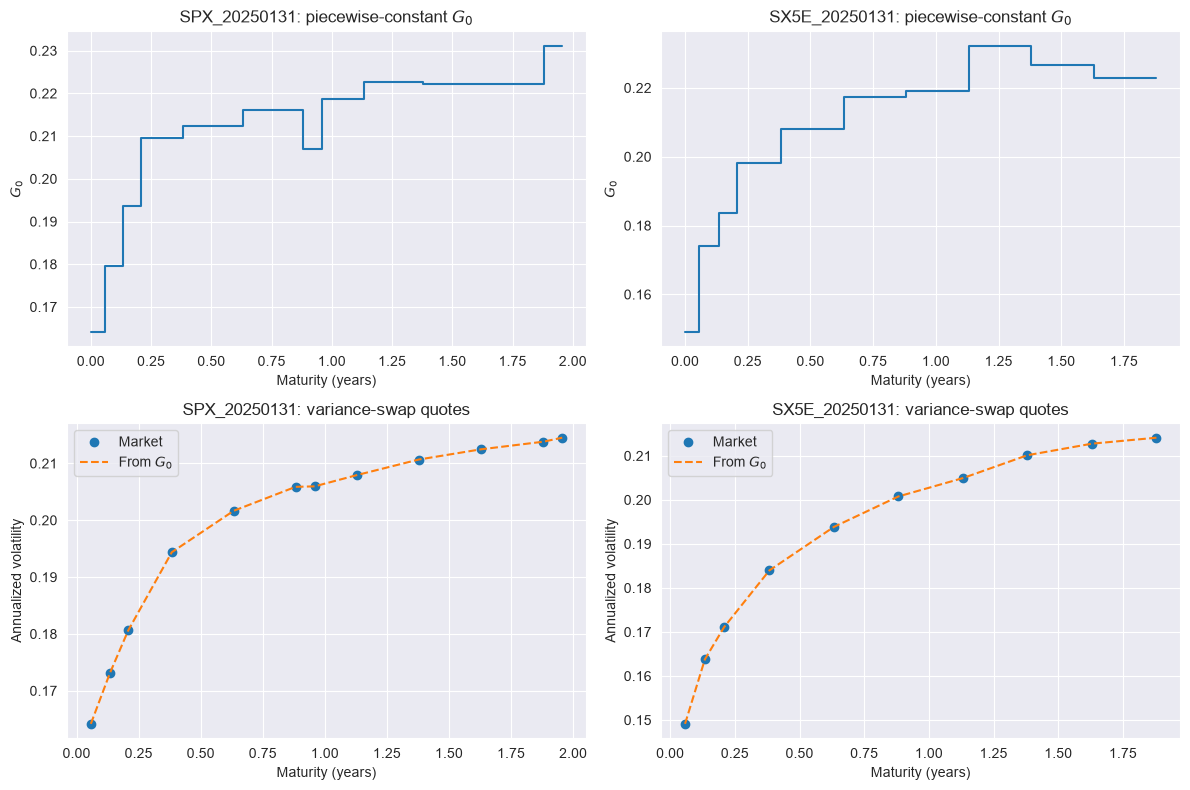

In [5]:
date = '20250131'
fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for column, asset_label in enumerate(('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'
    result = g0_results[dataset]
    boundaries = result['time_boundaries']
    values = result['G0_values']
    comparison = result['comparison']
    axes[0, column].step(boundaries, np.r_[values, values[-1]],
                         where='post', label=r'$G_0$')
    axes[0, column].set_title(rf'{dataset}: piecewise-constant $G_0$')
    axes[0, column].set_xlabel('Maturity (years)')
    axes[0, column].set_ylabel(r'$G_0$')
    axes[0, column].grid(True)
    axes[1, column].plot(comparison['maturity'],
                         comparison['variance_swap_quote'], 'o', label='Market')
    axes[1, column].plot(comparison['maturity'],
                         comparison['reconstructed_variance_swap_quote'],
                         '--', label=r'From $G_0$')
    axes[1, column].set_title(f'{dataset}: variance-swap quotes')
    axes[1, column].set_xlabel('Maturity (years)')
    axes[1, column].set_ylabel('Annualized volatility')
    axes[1, column].grid(True)
    axes[1, column].legend()
fig.tight_layout()
target = VARIANCE_SWAP_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(target / 'variance_swap_g0_calibration.png', dpi=200,
            bbox_inches='tight')
plt.show()


## 2025-07-31

In [6]:
for asset in ('SPX_20250731', 'SX5E_20250731'):
    data = clean_variance_swap_data(market_data[asset]['variance_swaps'])
    variance_swap_data[asset] = data

    maturities = data['maturity'].to_numpy(dtype=float)
    market_quotes = data['variance_swap_quote'].to_numpy(dtype=float)

    time_boundaries, G0_values = (
        compute_piecewise_constant_g0_from_variance_swaps(
            maturities,
            market_quotes,
        )
    )

    integrated_variances = np.array([
        integrated_piecewise_constant_g0_squared(
            T, time_boundaries, G0_values
        )
        for T in maturities
    ])
    reconstructed_quotes = np.sqrt(integrated_variances / maturities)

    comparison = data.copy()
    comparison['reconstructed_variance_swap_quote'] = reconstructed_quotes
    comparison['error'] = reconstructed_quotes - market_quotes

    g0_results[asset] = {
        'time_boundaries': time_boundaries,
        'G0_values': G0_values,
        'comparison': comparison,
    }

    print(f'\n{asset} - variance-swap calibration')
    print(f'Maximum reconstruction error: {np.max(np.abs(comparison["error"])):.3e}')



SPX_20250731 - variance-swap calibration
Maximum reconstruction error: 5.551e-17

SX5E_20250731 - variance-swap calibration
Maximum reconstruction error: 2.776e-17


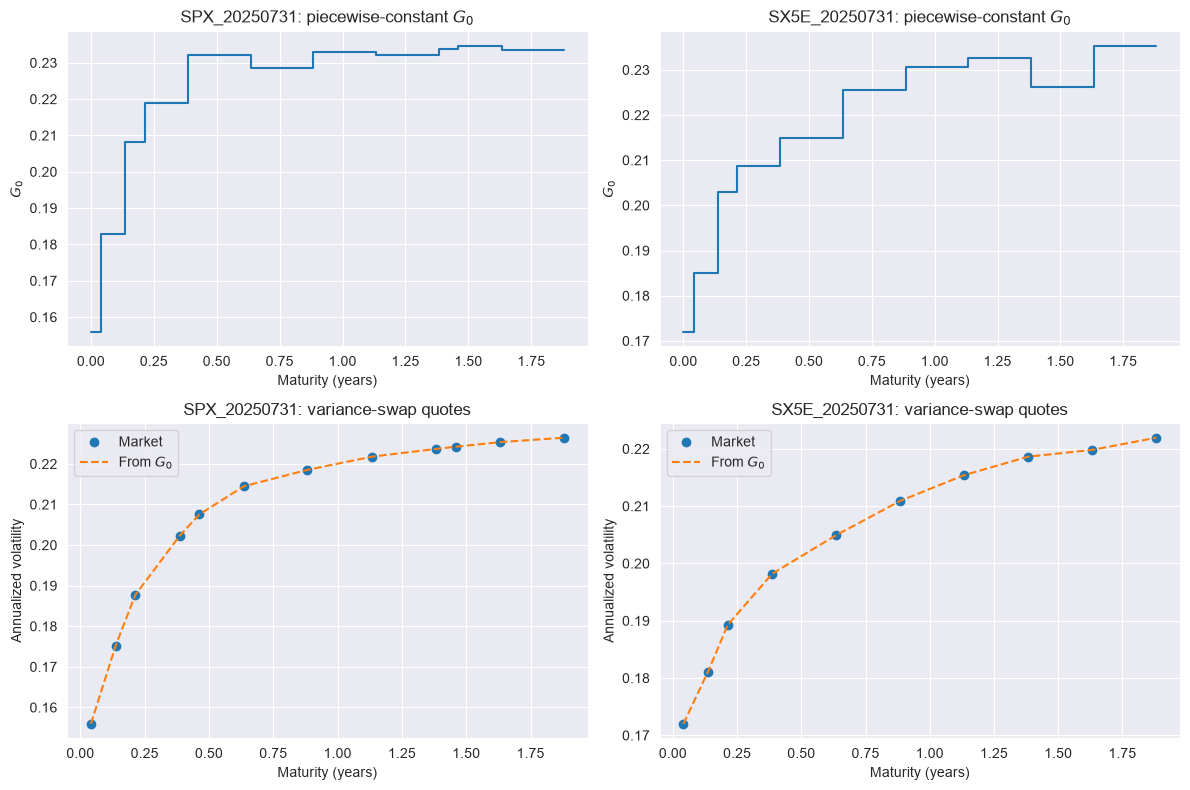

In [7]:
date = '20250731'
fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for column, asset_label in enumerate(('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'
    result = g0_results[dataset]
    boundaries = result['time_boundaries']
    values = result['G0_values']
    comparison = result['comparison']
    axes[0, column].step(boundaries, np.r_[values, values[-1]],
                         where='post', label=r'$G_0$')
    axes[0, column].set_title(rf'{dataset}: piecewise-constant $G_0$')
    axes[0, column].set_xlabel('Maturity (years)')
    axes[0, column].set_ylabel(r'$G_0$')
    axes[0, column].grid(True)
    axes[1, column].plot(comparison['maturity'],
                         comparison['variance_swap_quote'], 'o', label='Market')
    axes[1, column].plot(comparison['maturity'],
                         comparison['reconstructed_variance_swap_quote'],
                         '--', label=r'From $G_0$')
    axes[1, column].set_title(f'{dataset}: variance-swap quotes')
    axes[1, column].set_xlabel('Maturity (years)')
    axes[1, column].set_ylabel('Annualized volatility')
    axes[1, column].grid(True)
    axes[1, column].legend()
fig.tight_layout()
target = VARIANCE_SWAP_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(target / 'variance_swap_g0_calibration.png', dpi=200,
            bbox_inches='tight')
plt.show()


Pricing by Fourier at maturity $T$ uses the uniform grid $t_i = iT/N$, $i = 0,\dots,N-1$, and requires the values $G_0(t_i)$: for each $i$ we locate the interval
$[T_{k-1}, T_k)$ containing $t_i$ and set

$$
G_0(t_i) = \sqrt{\dfrac{T_k\,\sigma_{\mathrm{VS}}(T_k)^2 - T_{k-1}\,\sigma_{\mathrm{VS}}(T_{k-1})^2}{T_k - T_{k-1}}} .
$$

If $T \ge T_n$ and $i$ is such that $t_i \ge T_n$, the market gives no
information, so we extrapolate flat: $G_0(t_i)$ equals the value of $G_0$ on the last interval
$[T_{n-1}, T_n)$. This is done by the function `evaluate_piecewise_constant_g0_on_grid`.

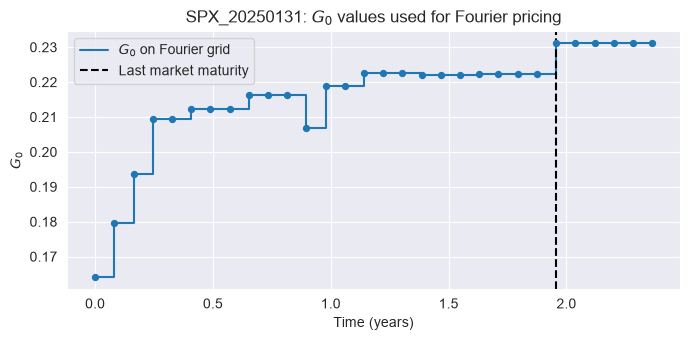

In [8]:
asset = next(iter(g0_results))
result = g0_results[asset]

# Use a maturity beyond the last market maturity to show flat extrapolation.
T = 1.25 * result['time_boundaries'][-1]
N = 30
time_grid = np.arange(N) * T / N
G0_grid = evaluate_piecewise_constant_g0_on_grid(
    T,
    N,
    result['time_boundaries'],
    result['G0_values'],
).reshape(-1)

plt.figure(figsize=(7, 3.5))
plt.step(time_grid, G0_grid, where='post', label=r'$G_0$ on Fourier grid')
plt.scatter(time_grid, G0_grid, s=18, zorder=3)
plt.axvline(
    result['time_boundaries'][-1],
    color='black',
    linestyle='--',
    label='Last market maturity',
)
plt.title(rf'{asset}: $G_0$ values used for Fourier pricing')
plt.xlabel('Time (years)')
plt.ylabel(r'$G_0$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ATM skew term-structure calibration

## Common one-dimensional model setup

The one-dimensional model setup is the same as in the HSBC notebook. In the
model, $S_0=F_T=1$ with zero rates and a martingale asset price. Hence the
model log-forward-moneyness is exactly $k=\log(K/F_T)=\log K$. We keep
$Y_0=1$ fixed and evaluate model and market skew at $\log(0.99)$ and
$\log(1.01)$.

In [9]:
from vss.parameters import compute_tilde_Gamma

n = d = 1
S_0 = 1.0
Y0_VALUE = 1.0

rho = np.array([[1.0]])
R_W = np.array([[1.0]])
Gamma = np.array([[1.0]])
tilde_Gamma = compute_tilde_Gamma(
    n=n,
    d=d,
    Gamma=Gamma,
)

log_moneyness = np.log(np.array([0.99, 1.01]))
SKEW_MONEYNESS = np.exp(log_moneyness)
strikes = S_0 * SKEW_MONEYNESS


def log_absolute_skew_residuals(model_skews, market_skews):
    """Return logarithmic residuals for absolute ATM skews."""

    model_skews = np.asarray(model_skews, dtype=float)
    market_skews = np.asarray(market_skews, dtype=float)
    if (
        not np.all(np.isfinite(model_skews))
        or not np.all(np.isfinite(market_skews))
        or np.any(np.abs(model_skews) <= 0.0)
        or np.any(np.abs(market_skews) <= 0.0)
    ):
        raise ValueError(
            'The absolute ATM skews must be finite and strictly positive '
            'before applying the logarithm.'
        )
    return np.log(np.abs(model_skews)) - np.log(np.abs(market_skews))

## Market ATM skew quotes

For each maturity the workbook supplies exactly two implied volatilities at
$k_-=\log(0.99)$ and $k_+=\log(1.01)$. The signed market ATM-skew estimate is

$$\mathrm{skew}(T)=\frac{\sigma_{\mathrm{impl}}(T,k_+)-
\sigma_{\mathrm{impl}}(T,k_-)}{k_+-k_-}.$$

No additional interpolation or maturity filter is applied. The calibration
minimizes errors in the logarithms of the absolute skews, as in the HSBC
notebook.


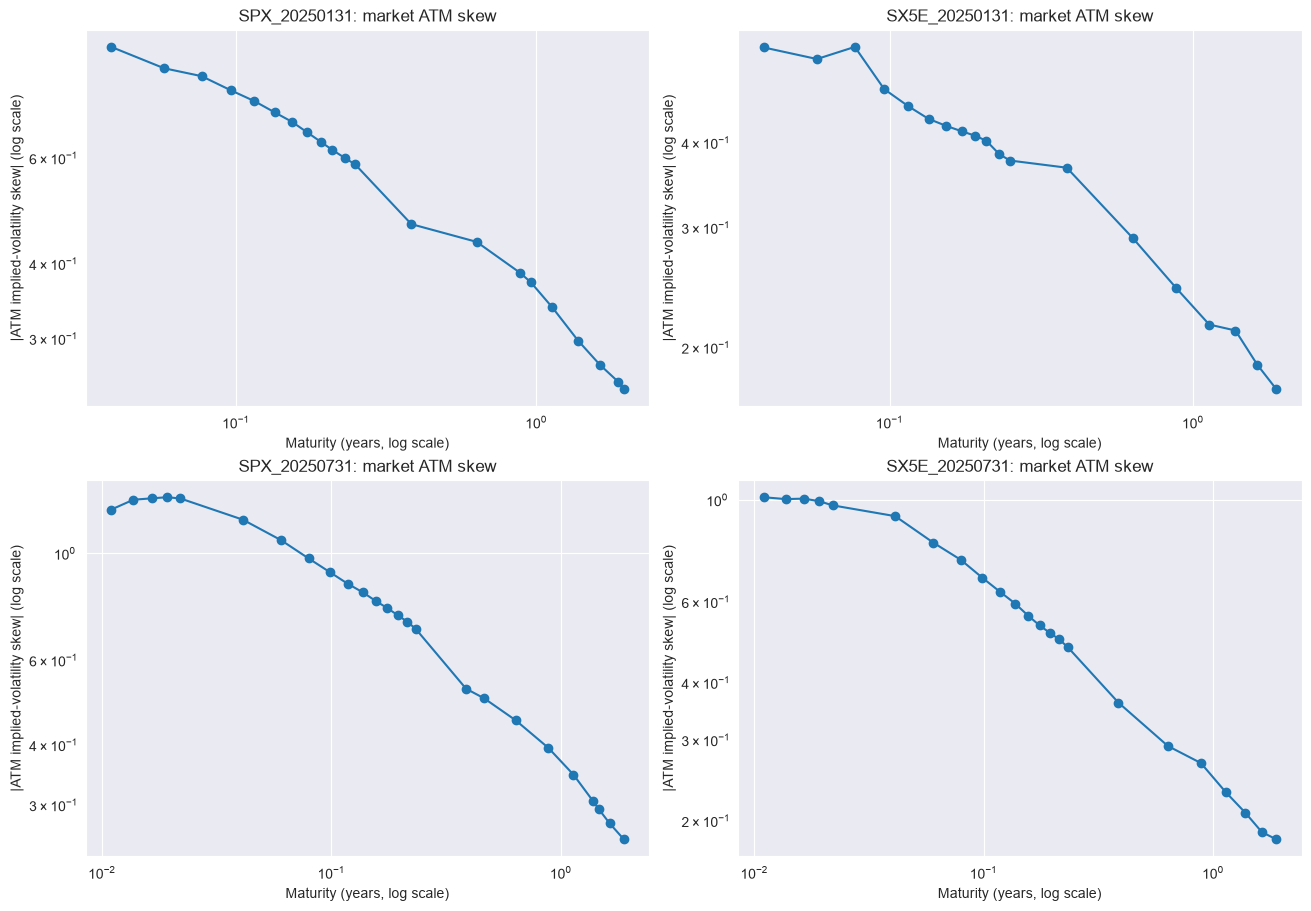

In [10]:
from vss.market_data.skew import compute_market_skew

market_skew_maturities = {}
market_skews = {}
market_implied_volatilities = {}

for dataset, sheets in market_data.items():
    surface = sheets['implied_volatility']
    maturities = surface.index.to_numpy(dtype=float)
    observed_moneyness = surface.columns.to_numpy(dtype=float)
    if surface.shape[1] != 2 or not np.allclose(
        np.log(observed_moneyness), log_moneyness, rtol=0.0, atol=1e-12
    ):
        raise ValueError(f'{dataset}: expected only 99% and 101% forward moneyness')
    values = surface.to_numpy(dtype=float)
    if not (np.isfinite(values).all() and np.all(values > 0)
            and np.isfinite(maturities).all() and np.all(maturities > 0)):
        raise ValueError(f'{dataset}: invalid implied-volatility observations')
    market_skew_maturities[dataset] = maturities
    market_implied_volatilities[dataset] = values
    market_skews[dataset] = compute_market_skew(
        maturities, log_moneyness, values
    )

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for row, date in enumerate(DATES):
    for column, asset_label in enumerate(('SPX', 'SX5E')):
        dataset = f'{asset_label}_{date}'
        axis = axes[row, column]
        axis.loglog(market_skew_maturities[dataset],
                    np.abs(market_skews[dataset]), 'o-')
        axis.set_title(f'{dataset}: market ATM skew')
        axis.set_xlabel('Maturity (years, log scale)')
        axis.set_ylabel('|ATM implied-volatility skew| (log scale)')
        axis.grid(True)
fig.savefig(MARKET_QUOTES_PLOTS_DIRECTORY / 'market_atm_skew_term_structures.png',
            dpi=200, bbox_inches='tight')
plt.show()


The following plots also show the two observed forward-moneyness volatility curves used for each skew; these are the prepared market points themselves.

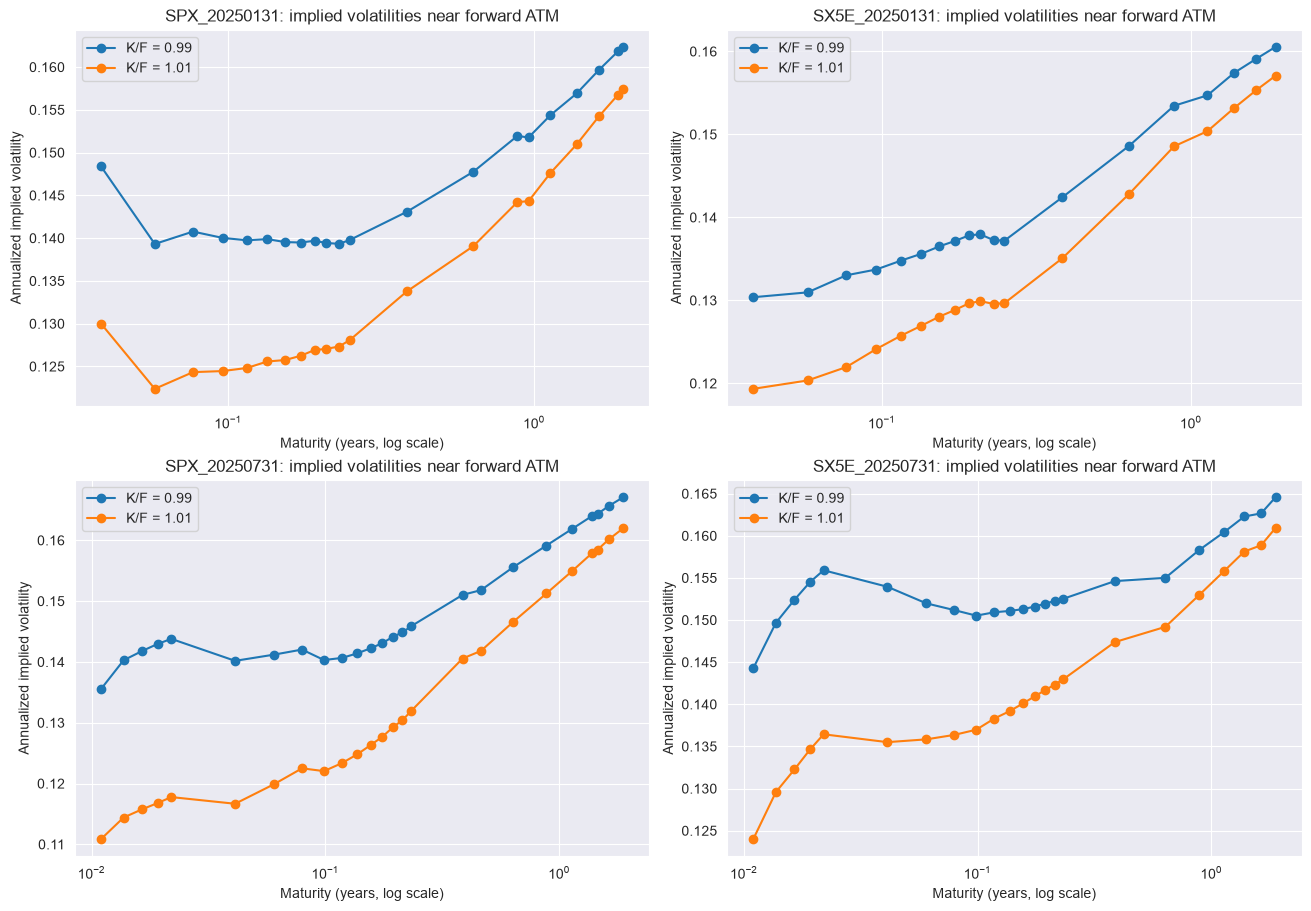

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for row, date in enumerate(DATES):
    for column, asset_label in enumerate(('SPX', 'SX5E')):
        dataset = f'{asset_label}_{date}'
        axis = axes[row, column]
        values = market_implied_volatilities[dataset]
        for j, moneyness in enumerate(SKEW_MONEYNESS):
            axis.semilogx(market_skew_maturities[dataset], values[:, j],
                          'o-', label=f'K/F = {moneyness:.2f}')
        axis.set_title(f'{dataset}: implied volatilities near forward ATM')
        axis.set_xlabel('Maturity (years, log scale)')
        axis.set_ylabel('Annualized implied volatility')
        axis.grid(True)
        axis.legend()
fig.savefig(MARKET_QUOTES_PLOTS_DIRECTORY / 'market_near_atm_implied_volatilities.png',
            dpi=200, bbox_inches='tight')
plt.show()

## Fourier numerical settings

The time-grid resolution and the Gauss-Laguerre quadrature degree must depend on the maturity to obtain sufficiently precise prices.

In [12]:
def fourier_time_gride_and_laguerre_rule_size(T):
    """Return the time-grid size and Laguerre degree for maturity T."""

    if T <= 0.01:
        N_time_steps, Q_laguerre = 20, 128
    elif T <= 0.10:
        N_time_steps, Q_laguerre = 30, 80
    elif T <= 0.50:
        N_time_steps, Q_laguerre = 40, 60
    elif T <= 1.0:
        N_time_steps, Q_laguerre = 50, 40
    else:
        N_time_steps, Q_laguerre = 80, 30

    return N_time_steps, Q_laguerre

In [13]:
def fourier_fractional_time_gride_and_laguerre_rule_size(T, H):
    """Return N and Q adapted to maturity T and fractional parameter H.

    For larger maturities or smaller H, the time discretization must be
    finer, so N is increased. At the same time, the Fourier-Laplace
    transforms decay faster, so fewer Gauss-Laguerre points are needed.
    """

    if not np.isfinite(T) or T <= 0.0:
        raise ValueError("T must be finite and strictly positive.")
    if not np.isfinite(H) or H <= 0.0:
        raise ValueError("H must be finite and strictly positive.")

    # Start from the generic maturity-dependent rule.
    N_base, Q_base = fourier_time_gride_and_laguerre_rule_size(T)

    # Smaller H means a rougher fractional kernel.
    if H <= 0.10:
        N_multiplier, Q_multiplier = 2.0, 0.50
    elif H <= 0.25:
        N_multiplier, Q_multiplier = 1.5, 0.75
    else:
        N_multiplier, Q_multiplier = 1.0, 1.0

    N_time_steps = int(np.ceil(N_base * N_multiplier))
    Q_laguerre = int(np.floor(Q_base * Q_multiplier))

    # Keep a minimum quadrature degree.
    Q_laguerre = max(Q_laguerre, 20)

    return N_time_steps, Q_laguerre

## Calibration plot helper

Each kernel produces market-versus-model ATM-skew plots for all four datasets.
Plot paths include the valuation date, so the two snapshots never overwrite one another.

In [14]:
def plot_kernel_calibration(dataset, kernel_name, file_stem, atm_results):
    """Plot one marginal ATM-skew calibration and display its parameters."""

    result = atm_results[dataset]
    fig, axis = plt.subplots(figsize=(7, 5))
    axis.loglog(
        result['maturities'], np.abs(result['market_skews']),
        'o', label='Market',
    )
    axis.loglog(
        result['maturities'], np.abs(result['model_skews']),
        '-s', markersize=4, label='Model',
    )
    parameter_text = ', '.join(
        f'{name}={value:.2g}'
        for name, value in zip(result['parameter_names'], result['parameters'])
    )
    axis.set_title(
        f'{dataset} ATM skew: {kernel_name}\n'
        f'K/F = (0.99, 1.01); {parameter_text}, Y0={Y0_VALUE:g} (fixed)'
    )
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('|ATM skew| (log scale)')
    axis.grid(True)
    axis.legend()
    fig.tight_layout()

    target = ATM_SKEW_PLOTS_DIRECTORY / dataset.split('_')[1]
    target.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        target / f'{dataset}_{file_stem}_calibration.png',
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()

    row = {
        'Dataset': dataset,
        'Calibration': 'ATM skew',
        'Calibrated parameters': ', '.join(result['parameter_names']),
        'Fixed parameters': f'Y0 = {Y0_VALUE:.6g}',
        'Log-skew RMSE': result['log_RMSE'],
        'Maximum log-skew error': result['maximum_log_error'],
    }
    row.update(dict(zip(result['parameter_names'], result['parameters'])))
    if 'a_1' in row:
        row['a_2'] = 1.0 - row['a_1']
    display(pd.DataFrame([row]))


## Fractional-kernel calibration

We calibrate the fractional kernel separately to the four CACIB index-date
datasets. It is obtained from `shifted_fractional_KK_SIG_d1_n1` by setting
$\delta=0$. The calibrated ATM-skew parameters are $H$, $\eta$, and $c$.
In every case, $Y_0$ and $\Gamma$ are fixed to 1.

The initial parameters, lower bounds and upper bounds below are preserved
exactly from the original notebook.


### General functions

In [15]:
atm_skew_results = {}


def build_fractional_objects(asset, T, N, H, eta, c):
    """Build the matrices and vectors needed for Fourier pricing with fractional kernel."""

    # Build the fractional kernel matrices KK and SIG_eta_free, then scale SIG_eta_free it by eta to obtain SIG.
    KK, SIG_eta_free = shifted_fractional_KK_SIG_d1_n1(
        N=N, T=T,
        H=H,
        delta=0.0,
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the previously calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices, then the Fourier covariance objects.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=True):
    """Return the fractional-kernel ATM skew at maturity T.

    If use_adaptive_resolution is False, use the generic Fourier rule.
    This keeps the numerical resolution fixed during calibration.
    """

    H, eta, c = parameters
    if use_adaptive_resolution:
        N, Q_laguerre = fourier_fractional_time_gride_and_laguerre_rule_size(T, H)
    else:
        N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_fractional_objects(
        asset, T, N, H, eta, c
    )
    # The skew formula uses the Fourier transform along the u-contour.
    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [16]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.8, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 ATM-skew parameters: [ 0.25968746  0.8        -0.99269752]
SPX_20250131 ATM-skew log RMSE: 3.380e-02


###### Calibration plots

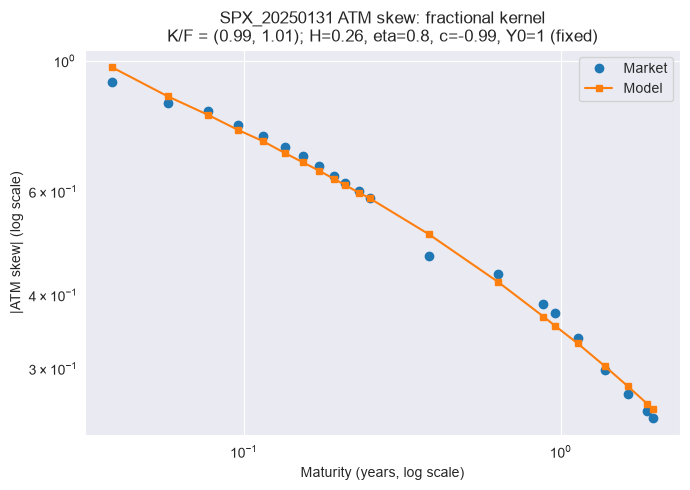

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SPX_20250131,ATM skew,"H, eta, c",Y0 = 1,0.033805,0.086148,0.259687,0.8,-0.992698


In [17]:
dataset = 'SPX_20250131'
plot_kernel_calibration(
    dataset, 'fractional kernel', 'fractional', atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [18]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 ATM-skew parameters: [ 0.223744    0.5        -0.84320566]
SX5E_20250131 ATM-skew log RMSE: 5.157e-02


###### Calibration plots

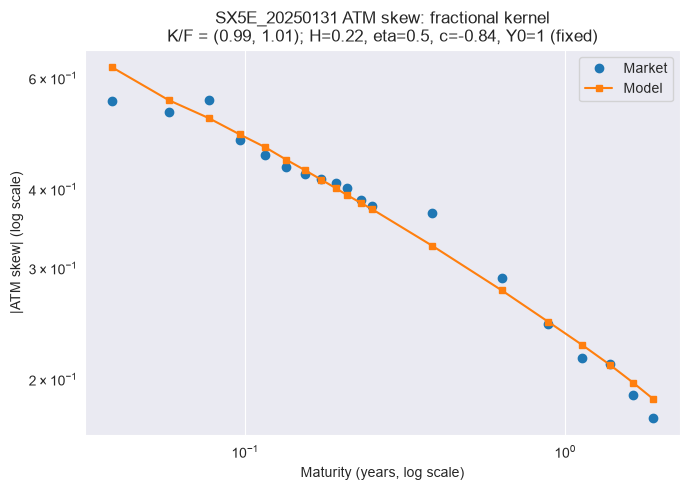

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250131,ATM skew,"H, eta, c",Y0 = 1,0.051566,0.122297,0.223744,0.5,-0.843206


In [19]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(
    dataset, 'fractional kernel', 'fractional', atm_skew_results
)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [20]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.95, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 ATM-skew parameters: [ 0.27274478  0.95       -0.99502555]
SPX_20250731 ATM-skew log RMSE: 6.837e-02


###### Calibration plots

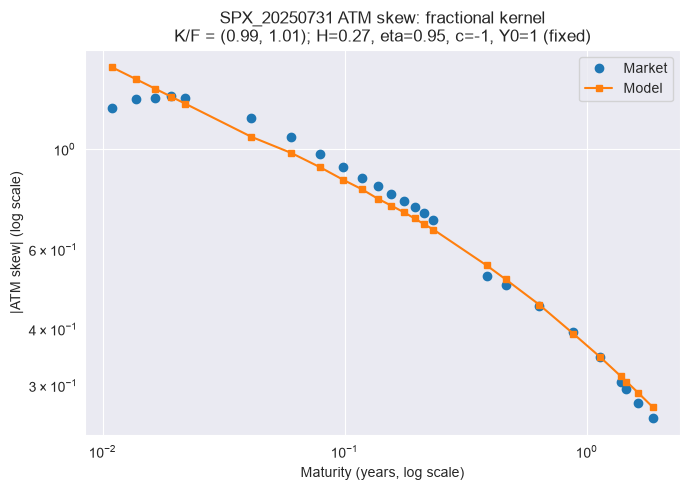

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SPX_20250731,ATM skew,"H, eta, c",Y0 = 1,0.068368,0.207468,0.272745,0.95,-0.995026


In [21]:
dataset = 'SPX_20250731'
plot_kernel_calibration(
    dataset, 'fractional kernel', 'fractional', atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [22]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 ATM-skew parameters: [ 0.17351136  0.5        -0.95228386]
SX5E_20250731 ATM-skew log RMSE: 1.042e-01


###### Calibration plots

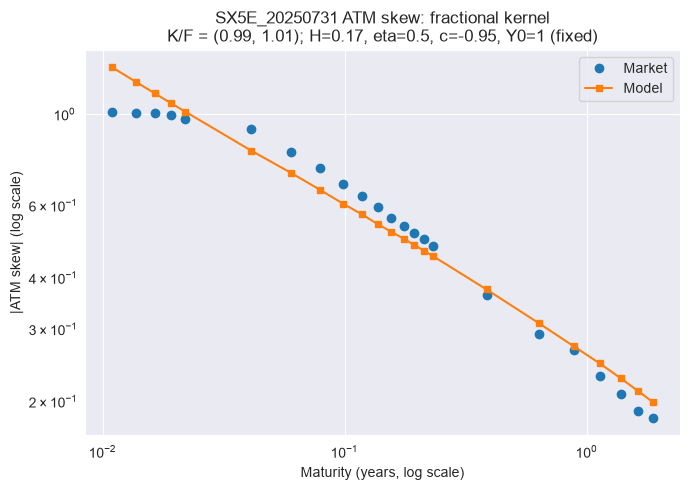

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250731,ATM skew,"H, eta, c",Y0 = 1,0.10417,0.248276,0.173511,0.5,-0.952284


In [23]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(
    dataset, 'fractional kernel', 'fractional', atm_skew_results
)


## Shifted fractional-kernel calibration

This section repeats the fixed-$Y_0$ ATM-skew calibration with the shifted
fractional kernel and the value used by the implementation,
$\delta=1/52$. Functions and results specific to this kernel are prefixed with
`shifted_fractional_`. The existing initial parameters and bounds are unchanged.


### General functions

The following functions build the shifted-fractional objects and compute the ATM skew.

In [24]:
shifted_fractional_atm_skew_results = {}


SHIFTED_FRACTIONAL_DELTA = 1 / 52.

def build_shifted_fractional_objects(asset, T, N, H, eta, c):
    """Build the Fourier-pricing objects for the shifted fractional kernel."""

    # Build the shifted fractional kernel matrices with delta = 5/252.
    KK, SIG_eta_free = shifted_fractional_KK_SIG_d1_n1(
        N=N, T=T,
        H=H,
        delta=SHIFTED_FRACTIONAL_DELTA,
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices used by the Fourier transform.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def shifted_fractional_atm_skew(asset, T, parameters):
    """Return the ATM skew for the shifted fractional kernel."""

    H, eta, c = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_shifted_fractional_objects(
        asset, T, N, H, eta, c
    )

    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [25]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.1, 0.3, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.8, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 shifted-fractional ATM-skew parameters: [ 0.14387114  0.78224509 -0.999     ]
SPX_20250131 shifted-fractional ATM-skew log RMSE: 3.234e-02


###### Calibration plots

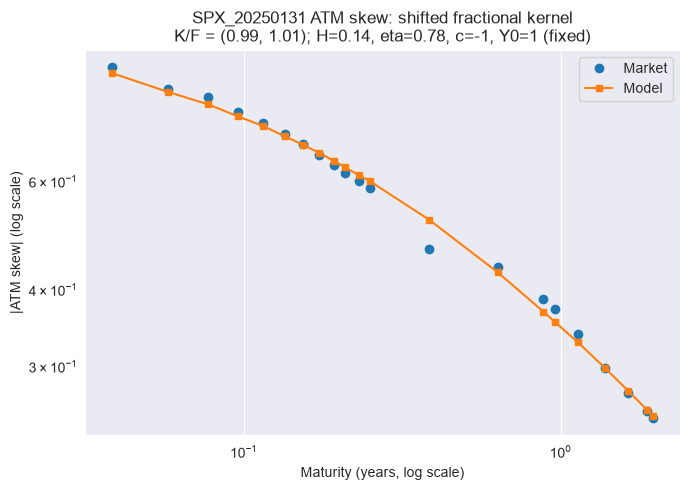

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SPX_20250131,ATM skew,"H, eta, c",Y0 = 1,0.032342,0.110139,0.143871,0.782245,-0.999


In [26]:
dataset = 'SPX_20250131'
plot_kernel_calibration(
    dataset, 'shifted fractional kernel', 'shifted_fractional', shifted_fractional_atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [27]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([0.30, 0.3, -0.8], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 shifted-fractional ATM-skew parameters: [ 0.08924456  0.5        -0.84893586]
SX5E_20250131 shifted-fractional ATM-skew log RMSE: 3.762e-02


###### Calibration plots

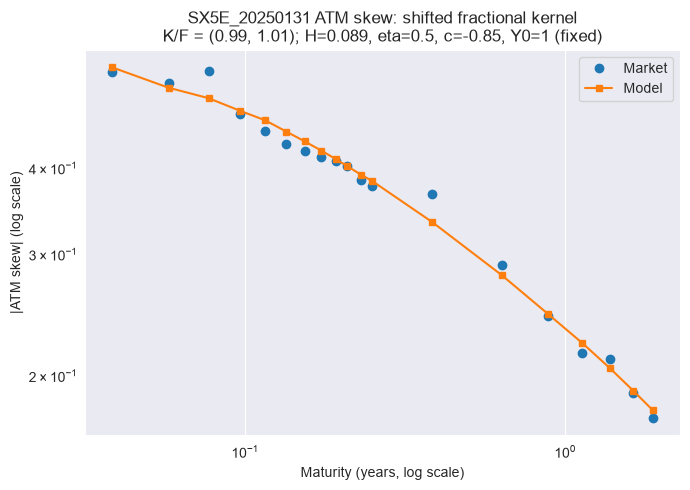

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250131,ATM skew,"H, eta, c",Y0 = 1,0.037623,0.095185,0.089245,0.5,-0.848936


In [28]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(
    dataset, 'shifted fractional kernel', 'shifted_fractional', shifted_fractional_atm_skew_results
)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [29]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.1, 0.6, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.95, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 shifted-fractional ATM-skew parameters: [ 0.10450227  0.9226168  -0.999     ]
SPX_20250731 shifted-fractional ATM-skew log RMSE: 3.570e-02


###### Calibration plots

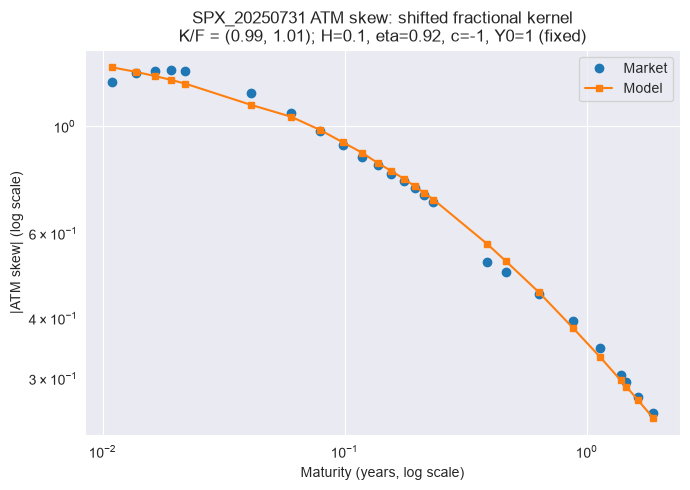

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SPX_20250731,ATM skew,"H, eta, c",Y0 = 1,0.035699,0.088478,0.104502,0.922617,-0.999


In [30]:
dataset = 'SPX_20250731'
plot_kernel_calibration(
    dataset, 'shifted fractional kernel', 'shifted_fractional', shifted_fractional_atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [31]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.30, 0.3, -0.8], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.9, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 shifted-fractional ATM-skew parameters: [-0.11622145  0.49323834 -0.999     ]
SX5E_20250731 shifted-fractional ATM-skew log RMSE: 3.708e-02


###### Calibration plots

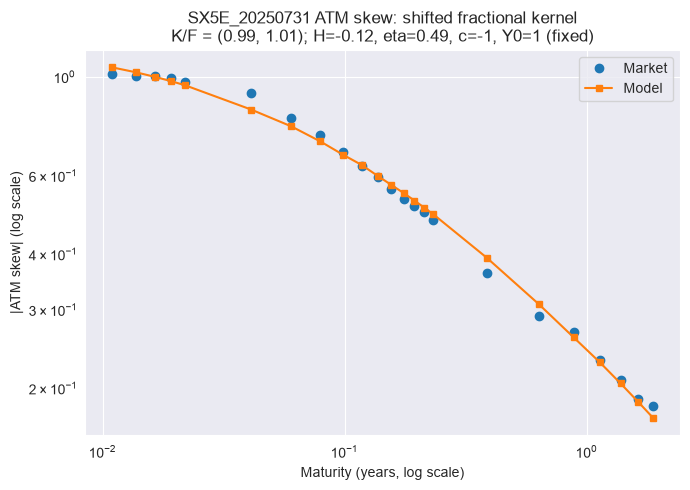

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250731,ATM skew,"H, eta, c",Y0 = 1,0.037076,0.087945,-0.116221,0.493238,-0.999


In [32]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(
    dataset, 'shifted fractional kernel', 'shifted_fractional', shifted_fractional_atm_skew_results
)


## One-exponential-kernel calibration

This section repeats the fixed-$Y_0$ calibration procedure with the one-exponential kernel $K(t,s)=\mathbf{1}_{s<t}\exp(-\kappa(t-s))$, with $\kappa\geq 0$. The calibrated parameters are $(\kappa,\eta,c)$. Functions and results specific to this kernel are prefixed with `one_exp_`.

**Prerequisites:** data extraction, the $G_0$ calibration, the common one-dimensional setup, market targets, and Fourier numerical settings.

### General functions

The following functions build the one-exponential objects and compute the ATM skew.

In [44]:
one_exp_atm_skew_results = {}


from vss.kernels.one_asset.sum_exponential import sum_exponential_KK_SIG_d1_n1


def build_one_exp_objects(asset, T, N, kappa, eta, c):
    """Build the Fourier-pricing objects for the one-exponential kernel."""

    KK, SIG_eta_free = sum_exponential_KK_SIG_d1_n1(
        N=N, T=T,
        kappa_array=np.array([[kappa]]),
        c_array=np.ones((1, 1)),
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices used by the Fourier transform.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def one_exp_atm_skew(asset, T, parameters):
    """Return the ATM skew for the one-exponential kernel."""

    kappa, eta, c = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_one_exp_objects(
        asset, T, N, kappa, eta, c
    )

    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [45]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([20.0, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.0, 0.01, -0.999], dtype=float)
upper_bounds = np.array([50.0, 2.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 one-exponential ATM-skew parameters: [ 1.50449853e-07  2.14957458e+00 -8.23617436e-01]
SPX_20250131 one-exponential ATM-skew log RMSE: 6.156e-02


###### Calibration plots

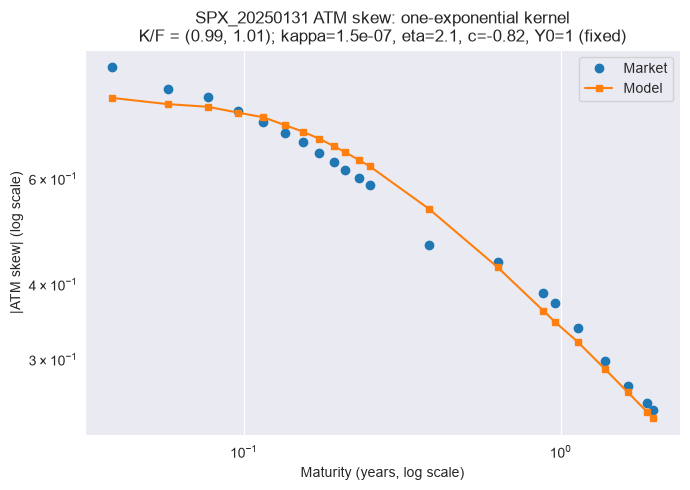

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa,eta,c
0,SPX_20250131,ATM skew,"kappa, eta, c",Y0 = 1,0.061563,0.137829,1.504499e-07,2.149575,-0.823617


In [46]:
dataset = 'SPX_20250131'
plot_kernel_calibration(
    dataset, 'one-exponential kernel', 'one_exp', one_exp_atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [47]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([30.0, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.0, 0.01, -0.999], dtype=float)
upper_bounds = np.array([50.0, 1.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 one-exponential ATM-skew parameters: [ 2.38078235  1.03727497 -0.999     ]
SX5E_20250131 one-exponential ATM-skew log RMSE: 7.826e-02


###### Calibration plots

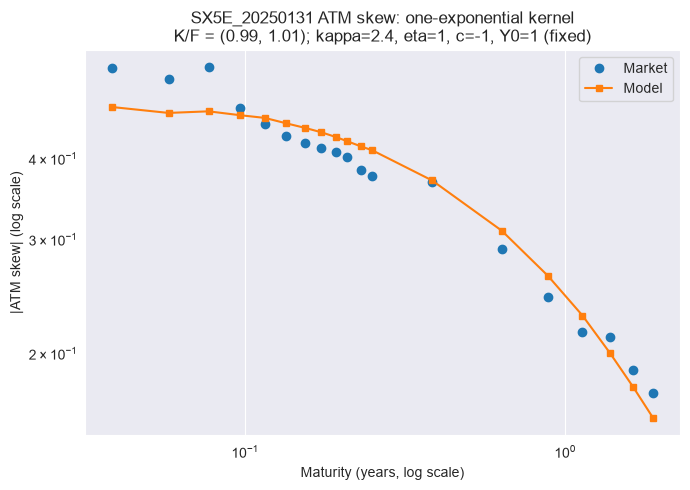

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa,eta,c
0,SX5E_20250131,ATM skew,"kappa, eta, c",Y0 = 1,0.078263,0.156307,2.380782,1.037275,-0.999


In [48]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(
    dataset, 'one-exponential kernel', 'one_exp', one_exp_atm_skew_results
)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [49]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([20.0, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.0, 0.01, -0.999], dtype=float)
upper_bounds = np.array([50.0, 3., -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 one-exponential ATM-skew parameters: [ 6.22460355e-07  3.00000000e+00 -8.48699590e-01]
SPX_20250731 one-exponential ATM-skew log RMSE: 5.745e-02


###### Calibration plots

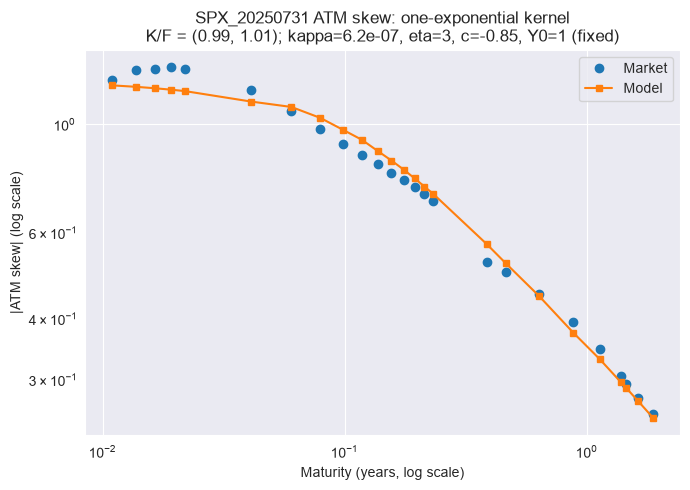

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa,eta,c
0,SPX_20250731,ATM skew,"kappa, eta, c",Y0 = 1,0.05745,0.106183,6.224604e-07,3.0,-0.8487


In [50]:
dataset = 'SPX_20250731'
plot_kernel_calibration(
    dataset, 'one-exponential kernel', 'one_exp', one_exp_atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [51]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([10.0, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.0, 0.01, -0.999], dtype=float)
upper_bounds = np.array([50.0, 3.1, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 one-exponential ATM-skew parameters: [ 0.12940744  3.1        -0.629302  ]
SX5E_20250731 one-exponential ATM-skew log RMSE: 6.579e-02


###### Calibration plots

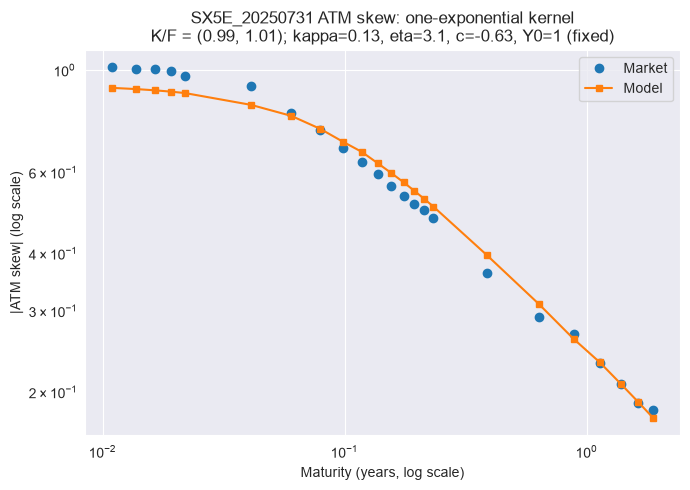

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa,eta,c
0,SX5E_20250731,ATM skew,"kappa, eta, c",Y0 = 1,0.065787,0.107706,0.129407,3.1,-0.629302


In [52]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(
    dataset, 'one-exponential kernel', 'one_exp', one_exp_atm_skew_results
)

## Two-exponential-kernel calibration

This section repeats the fixed-$Y_0$ calibration procedure with a sum of two exponential kernels. The kernel is $K(t,s)=\mathbf{1}_{s<t}[a_1\exp(-\kappa_1(t-s))+a_2\exp(-\kappa_2(t-s))]$, with $a_2=1-a_1$. Functions and results specific to this kernel are prefixed with `two_exp_`.

**Prerequisites:** data extraction, the $G_0$ calibration, the common one-dimensional setup, market targets, and Fourier numerical settings.

### General functions

The following functions build the two-exponential objects and compute the ATM skew.

In [33]:
two_exp_atm_skew_results = {}


from vss.kernels.one_asset.sum_exponential import sum_exponential_KK_SIG_d1_n1

def build_two_exp_objects(asset, T, N, kappa_1, kappa_2, a_1, eta, c):
    """Build the Fourier-pricing objects for the two-exponential kernel."""

    a_2 = 1.0 - a_1
    # Keep the rate-weight pairs aligned when the two rates are reordered.
    if kappa_1 > kappa_2:
        kappa_1, kappa_2 = kappa_2, kappa_1
        a_1, a_2 = a_2, a_1

    # Build the two-exponential kernel with normalized weights a_1 + a_2 = 1.
    KK, SIG_eta_free = sum_exponential_KK_SIG_d1_n1(
        N=N, T=T,
        kappa_array=np.array([[kappa_1, kappa_2]]),
        c_array=np.array([[a_1, a_2]]),
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices used by the Fourier transform.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def two_exp_atm_skew(asset, T, parameters):
    """Return the ATM skew for the two-exponential kernel."""

    kappa_1, kappa_2, a_1, eta, c = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_two_exp_objects(
        asset, T, N, kappa_1, kappa_2, a_1, eta, c
    )

    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [34]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5., 50.00, 1.00, 10., -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def two_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 two-exponential ATM-skew parameters: [ 0.65743296 24.88642883  0.45570756  2.3465546  -0.999     ]
SPX_20250131 two-exponential ATM-skew log RMSE: 2.597e-02


###### Calibration plots

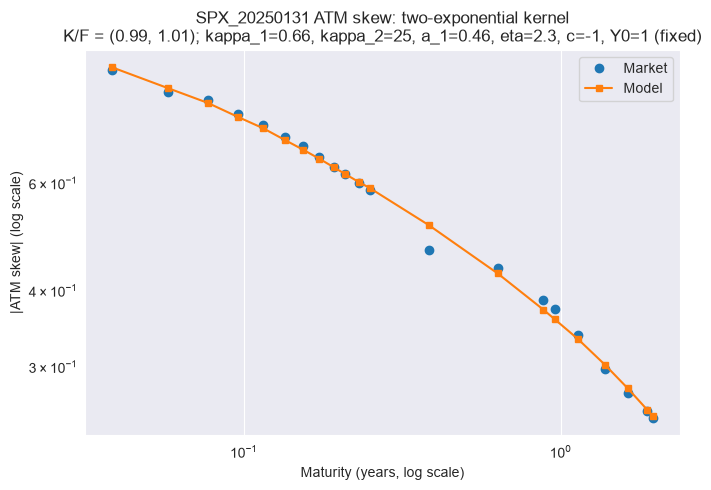

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2
0,SPX_20250131,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.025965,0.094702,0.657433,24.886429,0.455708,2.346555,-0.999,0.544292


In [35]:
dataset = 'SPX_20250131'
plot_kernel_calibration(
    dataset, 'two-exponential kernel', 'two_exp', two_exp_atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [36]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5., 50.00, 1.00, 10, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def two_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 two-exponential ATM-skew parameters: [ 1.32106127 32.38807409  0.49687819  1.43712293 -0.99349979]
SX5E_20250131 two-exponential ATM-skew log RMSE: 3.564e-02


###### Calibration plots

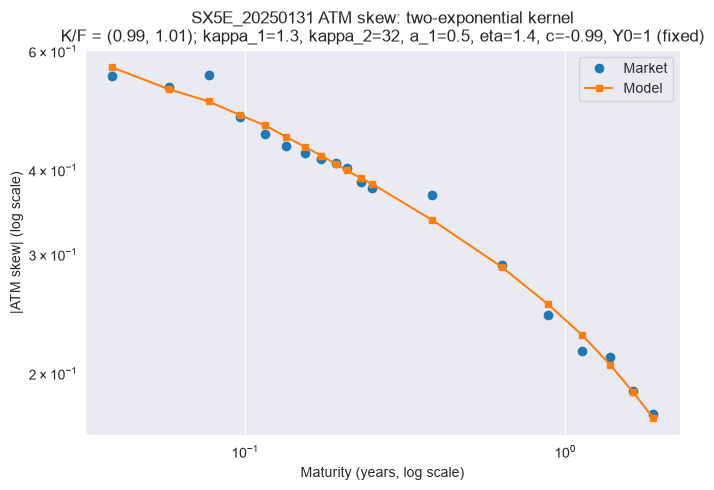

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2
0,SX5E_20250131,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.035639,0.089694,1.321061,32.388074,0.496878,1.437123,-0.9935,0.503122


In [37]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(
    dataset, 'two-exponential kernel', 'two_exp', two_exp_atm_skew_results
)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [38]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5.0, 50.00, 1.00, 10., -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def two_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 two-exponential ATM-skew parameters: [ 0.45406779 19.96145495  0.3760569   2.93690044 -0.99899974]
SPX_20250731 two-exponential ATM-skew log RMSE: 2.732e-02


###### Calibration plots

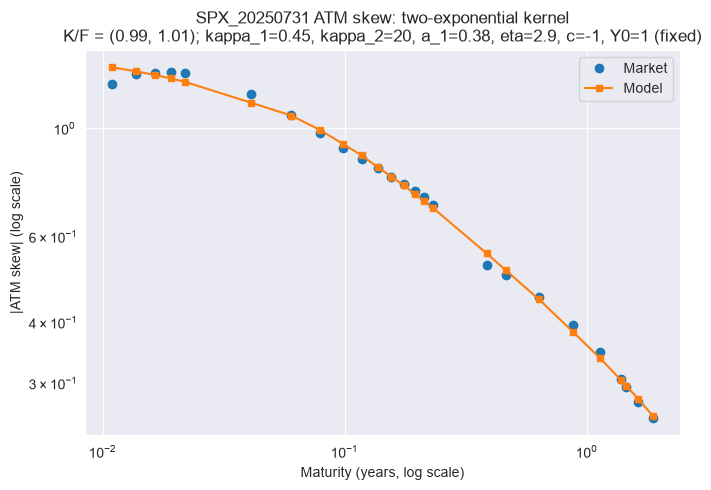

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2
0,SPX_20250731,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.027317,0.078641,0.454068,19.961455,0.376057,2.9369,-0.999,0.623943


In [39]:
dataset = 'SPX_20250731'
plot_kernel_calibration(
    dataset, 'two-exponential kernel', 'two_exp', two_exp_atm_skew_results
)


##### SX5E

###### ATM skew calibration

In [40]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5, 50, 1.00, 10, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()

def two_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 two-exponential ATM-skew parameters: [ 0.07793725 20.27214231  0.26363064  3.10673805 -0.74868058]
SX5E_20250731 two-exponential ATM-skew log RMSE: 1.978e-02


###### Calibration plots

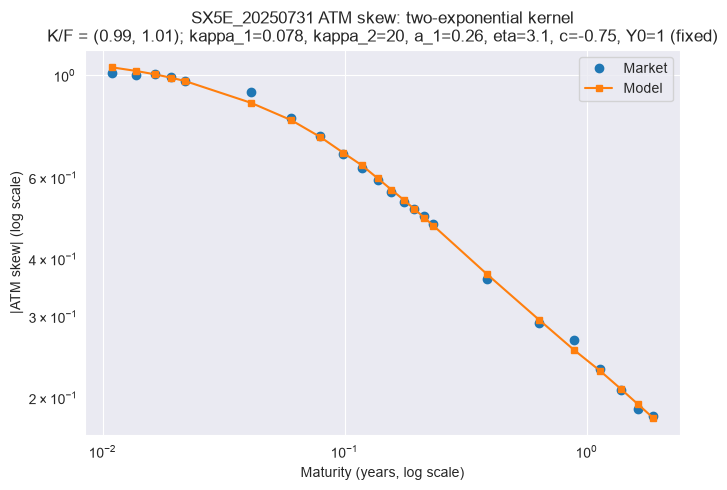

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2
0,SX5E_20250731,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.019783,0.055599,0.077937,20.272142,0.263631,3.106738,-0.748681,0.736369


In [41]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(
    dataset, 'two-exponential kernel', 'two_exp', two_exp_atm_skew_results
)


## Cross-kernel calibration results

This section compares the four ATM-skew calibrations for SPX and SX5E at each date.

In [53]:
kernel_results = [
    ('Fractional', atm_skew_results, 'tab:blue'),
    ('Shifted fractional', shifted_fractional_atm_skew_results, 'tab:orange'),
    ('One exponential', one_exp_atm_skew_results, 'tab:green'),
    ('Two exponentials', two_exp_atm_skew_results, 'tab:red'),
]
cross_kernel_calibration_summary_by_date = {}


### 2025-01-31

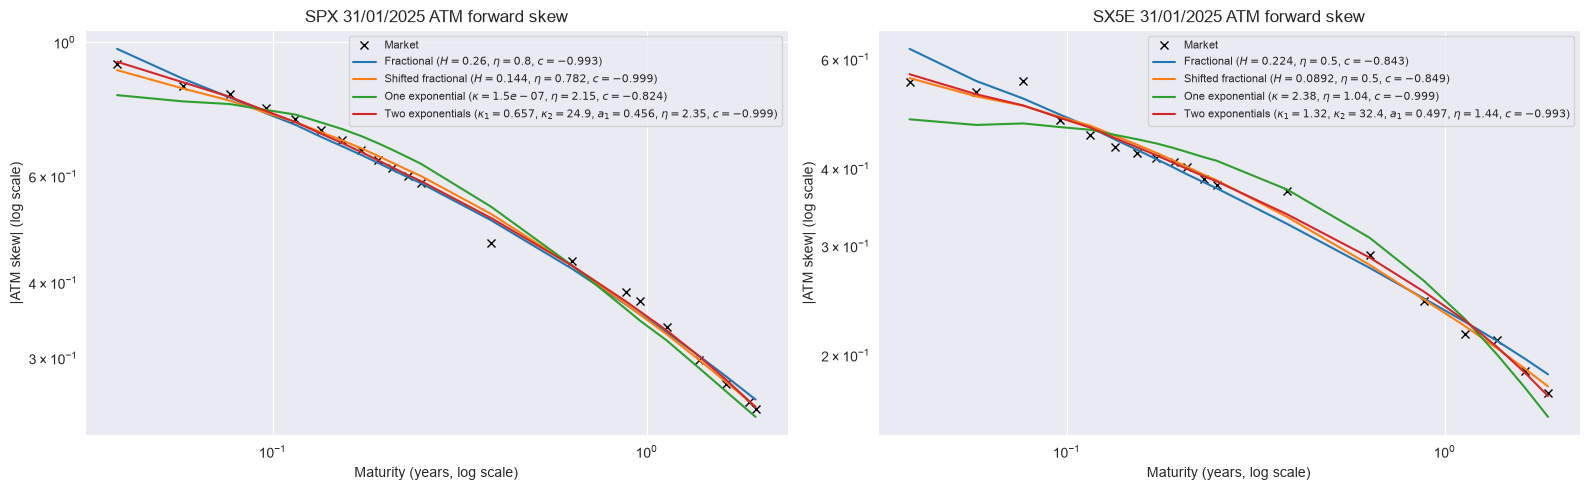

In [54]:
missing = []
for label, skew_results, _ in kernel_results:
    for dataset in ('SPX_20250131', 'SX5E_20250131'):
        if dataset not in skew_results:
            missing.append(f'{label} / {dataset} / ATM skew')
if missing:
    raise RuntimeError(
        f'Run all four kernel sections for 20250131 first; missing: {missing}'
    )

date = '20250131'
date_label = f'{date[6:8]}/{date[4:6]}/{date[:4]}'

PARAMETER_TEX = {
    'H': r'H',
    'kappa': r'\kappa',
    'eta': r'\eta',
    'c': r'c',
    'kappa_1': r'\kappa_1',
    'kappa_2': r'\kappa_2',
    'a_1': r'a_1',
}


def label_with_parameters(kernel_label, result):
    parameters = ', '.join(
        f'${PARAMETER_TEX[name]}={value:.3g}$'
        for name, value in zip(
            result['parameter_names'], result['parameters']
        )
    )
    return f'{kernel_label} ({parameters})'


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for axis, asset_label in zip(axes, ('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'
    market_result = kernel_results[0][1][dataset]
    axis.loglog(
        market_result['maturities'],
        np.abs(market_result['market_skews']),
        'x', color='black', label='Market',
    )
    for kernel_label, skew_results, color in kernel_results:
        result = skew_results[dataset]
        axis.loglog(
            result['maturities'],
            np.abs(result['model_skews']),
            '-', color=color,
            label=label_with_parameters(kernel_label, result),
        )
    axis.set_title(f'{asset_label} {date_label} ATM forward skew')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('|ATM skew| (log scale)')
    axis.grid(True)
    axis.legend(fontsize=8)

fig.tight_layout()
target = ATM_SKEW_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(
    target / 'cross_kernel_atm_skew_results.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()


### 2025-07-31

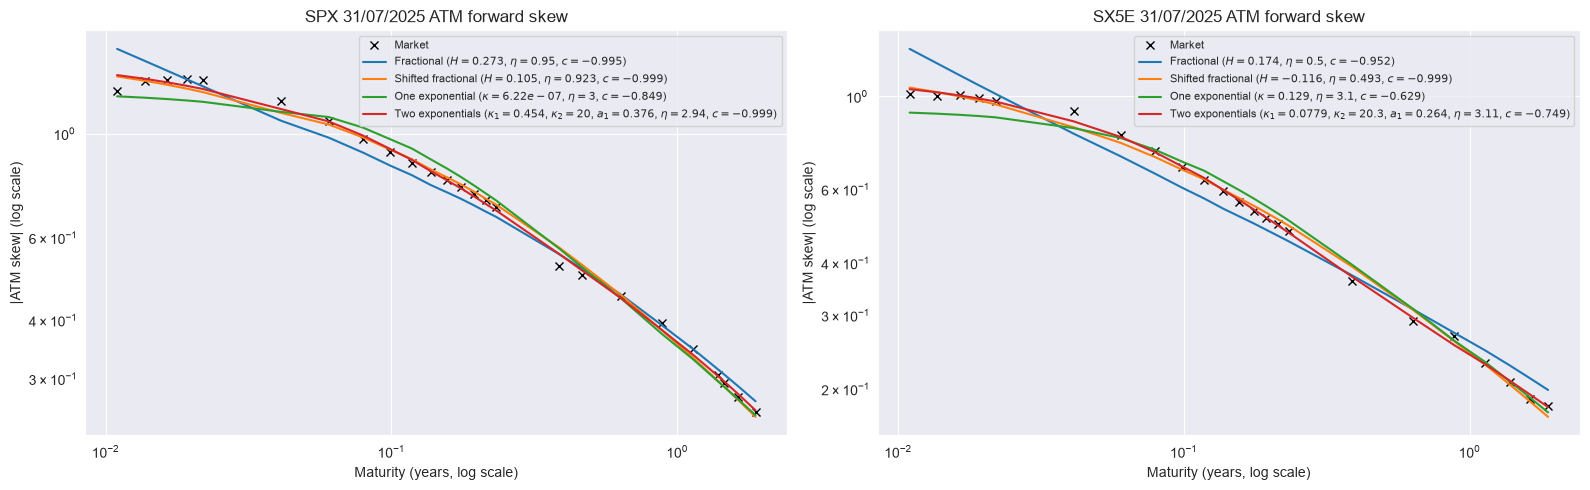

In [56]:
missing = []
for label, skew_results, _ in kernel_results:
    for dataset in ('SPX_20250731', 'SX5E_20250731'):
        if dataset not in skew_results:
            missing.append(f'{label} / {dataset} / ATM skew')
if missing:
    raise RuntimeError(
        f'Run all four kernel sections for 20250731 first; missing: {missing}'
    )

date = '20250731'
date_label = f'{date[6:8]}/{date[4:6]}/{date[:4]}'

PARAMETER_TEX = {
    'H': r'H',
    'kappa': r'\kappa',
    'eta': r'\eta',
    'c': r'c',
    'kappa_1': r'\kappa_1',
    'kappa_2': r'\kappa_2',
    'a_1': r'a_1',
}


def label_with_parameters(kernel_label, result):
    parameters = ', '.join(
        f'${PARAMETER_TEX[name]}={value:.3g}$'
        for name, value in zip(
            result['parameter_names'], result['parameters']
        )
    )
    return f'{kernel_label} ({parameters})'


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for axis, asset_label in zip(axes, ('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'
    market_result = kernel_results[0][1][dataset]
    axis.loglog(
        market_result['maturities'],
        np.abs(market_result['market_skews']),
        'x', color='black', label='Market',
    )
    for kernel_label, skew_results, color in kernel_results:
        result = skew_results[dataset]
        axis.loglog(
            result['maturities'],
            np.abs(result['model_skews']),
            '-', color=color,
            label=label_with_parameters(kernel_label, result),
        )
    axis.set_title(f'{asset_label} {date_label} ATM forward skew')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('|ATM skew| (log scale)')
    axis.grid(True)
    axis.legend(fontsize=8)

fig.tight_layout()
target = ATM_SKEW_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(
    target / 'cross_kernel_atm_skew_results.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()


# Call vs Call ATM term-structure calibration

The market payoff is assumed to be

$$
\frac12\left(\frac{S_T^{\mathrm{SPX}}}{S_0^{\mathrm{SPX}}}-1\right)^+
+\frac12\left(\frac{S_T^{\mathrm{SX5E}}}{S_0^{\mathrm{SX5E}}}-1\right)^+
-\left[
\frac12\left(
\frac{S_T^{\mathrm{SPX}}}{S_0^{\mathrm{SPX}}}
+\frac{S_T^{\mathrm{SX5E}}}{S_0^{\mathrm{SX5E}}}
\right)-1
\right]^+.
$$

Thus $S_0=(1,1)$ and the common strike is $K=1$. The three CVC quotes dated
29 January 2025 use the marginal SPX and SX5E calibrations dated 31 January
2025; the 29 July quotes use the marginal calibrations dated 31 July. For each
ordered pair of kernels, all marginal parameters are fixed and one constant
cross-asset correlation $\rho$ is fitted jointly to the three maturities.

The calibration residuals are simple relative price errors,

$$
r_j(\rho)=\frac{CVC_{\mathrm{model}}(T_j;\rho)
-CVC_{\mathrm{market}}(T_j)}{CVC_{\mathrm{market}}(T_j)}.
$$


## Market Call vs Call quotes

Call vs Call quotes: 20250129


,maturity,call_vs_call_quote
0,0.389041,0.002999
1,0.887671,0.004594
2,1.884932,0.006915


Call vs Call quotes: 20250729


,maturity,call_vs_call_quote
0,0.391781,0.002499
1,1.389041,0.005495
2,2.386301,0.007173


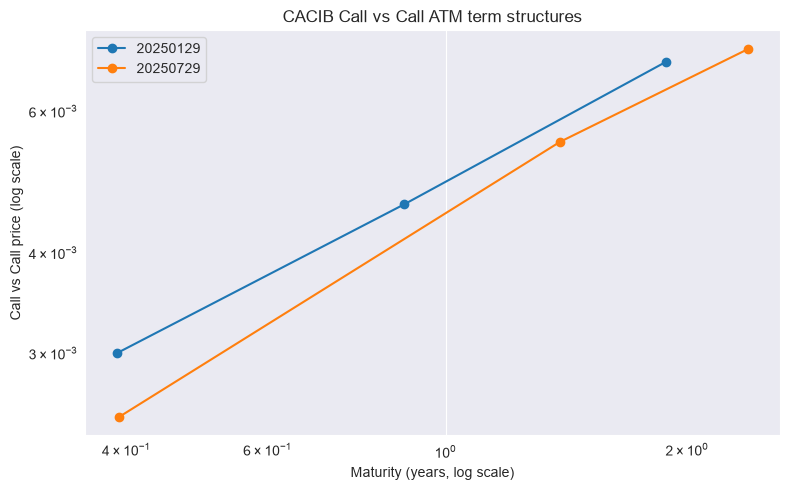

In [57]:
CVC_FILES = {
    '20250129': MARKET_DATA_DIR / 'cvc_SP500_SX5E_20250129.xlsx',
    '20250729': MARKET_DATA_DIR / 'cvc_SP500_SX5E_20250729.xlsx',
}
CVC_TO_MARGINAL_DATE = {
    '20250129': '20250131',
    '20250729': '20250731',
}

cvc_market_data = {}
for cvc_date, cvc_file in CVC_FILES.items():
    data = pd.read_excel(cvc_file)
    expected_columns = ['maturity', 'call_vs_call_quote']
    if data.columns.tolist() != expected_columns:
        raise ValueError(
            f'{cvc_file.name}: expected columns {expected_columns}, '
            f'got {data.columns.tolist()}'
        )
    data = data.loc[
        pd.to_numeric(data['maturity'], errors='raise')
        <= MAX_CVC_MATURITY_YEARS + 1e-12
    ].copy().reset_index(drop=True)
    if data.empty:
        raise ValueError(f'{cvc_file.name}: no observation within the selected horizon')
    values = data[expected_columns].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f'{cvc_file.name}: non-finite observation')
    if np.any(values <= 0.0) or np.any(np.diff(values[:, 0]) <= 0.0):
        raise ValueError(
            f'{cvc_file.name}: maturities and quotes must be positive, '
            'with strictly increasing maturities'
        )
    cvc_market_data[cvc_date] = data.copy()
    print(f'Call vs Call quotes: {cvc_date}')
    display(data)

fig, axis = plt.subplots(figsize=(8, 5))
for cvc_date, data in cvc_market_data.items():
    axis.loglog(
        data['maturity'], data['call_vs_call_quote'],
        'o-', label=cvc_date,
    )
axis.set_xlabel('Maturity (years, log scale)')
axis.set_ylabel('Call vs Call price (log scale)')
axis.set_title('CACIB Call vs Call ATM term structures')
axis.grid(True)
axis.legend()
fig.tight_layout()
fig.savefig(
    MARKET_QUOTES_PLOTS_DIRECTORY / 'market_cvc_term_structures.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()


## General functions

For each date, retained kernel pair and maturity, the following quantities do
not depend on $\rho$ and are prepared once for each numerical resolution:

- the fixed marginal ATM-skew parameters $(\nu_i,c_i)$ and the kernel parameters, read directly from `CVC_MARGINAL_PARAMETERS`;
- the common maturity-dependent Fourier time grid and Gauss-Laguerre rule;
- the marginal and joint Fourier integration points;
- the two calibrated marginal curves $g_0^i$, evaluated on the Fourier left grid by
  `evaluate_piecewise_constant_g0_on_grid` and stored as an array of shape `(N, 2)`;
  If a CVC maturity extends beyond the final variance-swap boundary, the
  evaluation function extrapolates the last calibrated value as a constant;
- `KK` and `SIG_integrals` for the selected pair of kernels;
- the two marginal Fourier-Laplace transforms used for the individual calls.

For the $d=n=2$ specialization of Example 1.1, the true matrix is
$G_0(t)=D(t)A(t)^{1/2}$ and the effective loading entering `MM` is
$G_0(t)A(t)^{-1/2}=D(t)$. The code therefore constructs `MM` directly with
`compute_M_matrix_d2_n2`; it does not interpret the two marginal $g_0^i$
curves as the diagonal of the joint matrix $G_0$.

For each candidate $\rho$, the code constructs $\rho_B(\rho)$ and
$R_W(\rho)$, then recomputes `SIG`, the Example 1.1 matrix `MM`, `V`, `sqrt_V`, `g_tilde`, the joint
Fourier-Laplace transform and the CVC price. No marginal model parameter is
recalibrated in this section.

The CVC optimization uses a dedicated numerical rule because its
two-dimensional basket integral requires $2Q^2$ joint transforms, instead of
$Q$ transforms for a marginal Lewis integral. For 29/01/2025, the three
maturities $T=(0.389041,0.887671,1.884932)$ use respectively
$(N,Q)=((20,30),(25,30),(30,30))$. For 29/07/2025, the three maturities
$T=(0.391781,1.389041,2.386301)$ use respectively
$(N,Q)=((20,30),(30,30),(30,30))$. The calibration and validation rules are
currently identical. Consequently, the calibration-grid and validation-grid
prices coincide; the validation interface is retained as an explicit hook for
a future finer-grid assessment.


In [65]:
CVC_ALPHA = np.array([0.25, 0.25])
CVC_S0 = np.ones(2)
CVC_STRIKE = np.array([1.0])
CVC_INITIAL_RHO = 0.8
CVC_LOWER_RHO = -0.999
CVC_UPPER_RHO = 0.999


def cvc_fourier_time_grid_size(T):
    """Return the Fourier time-grid size used by the CVC section."""

    if T <= 0.01:
        return 20
    if T <= 0.10:
        return 30
    if T <= 0.50:
        return 20
    if T <= 1.0:
        return 25
    return 30


def cvc_calibration_fourier_time_grid_and_laguerre_rule_size(T):
    """Return the Fourier time-grid size and CVC calibration degree."""

    N_time_steps = cvc_fourier_time_grid_size(T)
    if T <= 0.01:
        Q_laguerre = 32
    elif T <= 0.10:
        Q_laguerre = 30
    elif T <= 0.50:
        Q_laguerre = 30
    elif T <= 1.0:
        Q_laguerre = 30
    else:
        Q_laguerre = 30

    return N_time_steps, Q_laguerre


def cvc_validation_fourier_time_grid_and_laguerre_rule_size(T):
    """Return the Fourier time-grid size and CVC validation degree."""

    N_time_steps, Q_laguerre = cvc_calibration_fourier_time_grid_and_laguerre_rule_size(T)
    return N_time_steps, Q_laguerre

CVC_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'call vs call'
CVC_PLOTS_DIRECTORY.mkdir(parents=True, exist_ok=True)

KERNEL_LABELS = {
    'shifted_fractional': 'Shifted fractional',
    'two_exp': 'Two exponentials',
}
CVC_SHIFTED_FRACTIONAL_DELTA = 1 / 52

CVC_MARGINAL_PARAMETERS = {
    'SPX_20250131': {
        'shifted_fractional': {
            'H': 0.143871, 'eta': 0.782245, 'c': -0.999,
        },
        'two_exp': {
            'kappa_1': 0.657, 'kappa_2': 24.9, 'a_1': 0.456,
            'eta': 2.35, 'c': -0.999,
        },
    },
    'SX5E_20250131': {
        'shifted_fractional': {
            'H': 0.089245, 'eta': 0.5, 'c': -0.848936,
        },
        'two_exp': {
            'kappa_1': 1.32, 'kappa_2': 32.4, 'a_1': 0.497,
            'eta': 1.44, 'c': -0.993,
        },
    },
    'SPX_20250731': {
        'shifted_fractional': {
            'H': 0.105, 'eta': 0.923, 'c': -0.999,
        },
        'two_exp': {
            'kappa_1': 0.454, 'kappa_2': 20.0, 'a_1': 0.376,
            'eta': 2.94, 'c': -0.999,
        },
    },
    'SX5E_20250731': {
        'shifted_fractional': {
            'H': -0.116, 'eta': 0.493, 'c': -0.999,
        },
        'two_exp': {
            'kappa_1': 0.0779, 'kappa_2': 20.3, 'a_1': 0.264,
            'eta': 3.11, 'c': -0.749,
        },
    },
}


def cvc_marginal_specification(kernel_key, dataset):
    """Return one calibrated marginal model in a common representation."""

    try:
        parameters = CVC_MARGINAL_PARAMETERS[dataset][kernel_key]
    except KeyError as error:
        raise KeyError(
            f'Missing fixed marginal parameters for {dataset} / {kernel_key}'
        ) from error
    result = {
        'parameter_names': tuple(parameters),
        'parameters': np.array(list(parameters.values()), dtype=float),
    }
    specification = {
        'kernel_key': kernel_key,
        'dataset': dataset,
        'result': result,
        'nu': float(parameters['eta']),
        'c': float(parameters['c']),
    }

    if kernel_key == 'shifted_fractional':
        specification.update({
            'kind': 'fractional',
            'H': float(parameters['H']),
            'delta': float(CVC_SHIFTED_FRACTIONAL_DELTA),
        })
    elif kernel_key == 'two_exp':
        kappa_1 = float(parameters['kappa_1'])
        kappa_2 = float(parameters['kappa_2'])
        a_1 = float(parameters['a_1'])
        if kappa_1 > kappa_2:
            kappa_1, kappa_2 = kappa_2, kappa_1
            a_1 = 1.0 - a_1
        specification.update({
            'kind': 'exponential',
            'kappa': np.array([kappa_1, kappa_2], dtype=float),
            'weights': np.array([a_1, 1.0 - a_1], dtype=float),
        })
    else:
        raise ValueError(f'Unknown kernel key: {kernel_key}')

    return specification


def build_cvc_two_asset_kernel(T, N, spx_specification, sx5e_specification):
    """Build KK and SIG_integrals for one ordered pair of marginal kernels."""

    specifications = (spx_specification, sx5e_specification)
    kinds = tuple(specification['kind'] for specification in specifications)

    if kinds == ('fractional', 'fractional'):
        return shifted_fractional_KK_SIG_d2_n2(
            N=N,
            T=T,
            H_array=np.array([specification['H'] for specification in specifications]),
            delta_array=np.array([
                specification['delta'] for specification in specifications
            ]),
        )

    if kinds == ('exponential', 'exponential'):
        kappa_array = np.vstack([
            specification['kappa'] for specification in specifications
        ])
        weights_array = np.vstack([
            specification['weights'] for specification in specifications
        ])
        return sum_exponential_KK_SIG_d2_n2(
            N=N,
            T=T,
            kappa_array=kappa_array,
            c_array=weights_array,
        )

    raise ValueError(f'Unsupported kernel kinds: {kinds}')


def build_cvc_marginal_kernel(T, N, specification):
    """Build the one-dimensional kernel matrices for an inherited marginal model."""

    if specification['kind'] == 'fractional':
        return shifted_fractional_KK_SIG_d1_n1(
            N=N,
            T=T,
            H=specification['H'],
            delta=specification['delta'],
        )
    return sum_exponential_KK_SIG_d1_n1(
        N=N,
        T=T,
        kappa_array=specification['kappa'].reshape(1, -1),
        c_array=specification['weights'].reshape(1, -1),
    )


def cvc_g0_grid(dataset, T, N):
    """Evaluate one calibrated G0 curve on the Fourier left grid."""

    result = g0_results[dataset]
    return evaluate_piecewise_constant_g0_on_grid(
        T,
        N,
        result['time_boundaries'],
        result['G0_values'],
    )


def cvc_marginal_fourier_values(T, N, nodes, specification):
    """Compute a marginal transform once; it is independent of cross-asset rho."""

    KK, SIG_eta_free = build_cvc_marginal_kernel(T, N, specification)
    eta_matrix = np.array([[specification['nu']]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    rho_one = np.ones((1, 1))
    R_W_one = np.ones((1, 1))
    C_one = np.array([[specification['c']]])
    Gamma_one = np.ones((1, 1))
    tilde_Gamma_one = compute_tilde_Gamma(1, 1, Gamma_one)
    Y0_one = np.ones(1)
    G0_one = cvc_g0_grid(specification['dataset'], T, N)

    MM = compute_M_matrix(
        n=1,
        d=1,
        N=N,
        SIG=SIG,
        Gamma=Gamma_one,
        tilde_Gamma=tilde_Gamma_one,
        rho=rho_one,
        G0=G0_one,
        Y0=Y0_one,
    )
    V = compute_V_matrix_for_fourier(
        1, N, T, eta_matrix, R_W_one, KK, SIG, MM
    )
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_one, 1, N, MM)
    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    return vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, 1, 1, N, T, C_one, rho_one,
        R_W_one, V, sqrt_V, g_tilde,
    )


def prepare_cvc_kernel_pair(
    cvc_date,
    spx_kernel,
    sx5e_kernel,
    rule_size_function,
    resolution_label,
):
    """Prepare all rho-independent quantities at one CVC resolution."""

    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    spx_dataset = f'SPX_{marginal_date}'
    sx5e_dataset = f'SX5E_{marginal_date}'
    spx_specification = cvc_marginal_specification(spx_kernel, spx_dataset)
    sx5e_specification = cvc_marginal_specification(sx5e_kernel, sx5e_dataset)

    eta_matrix = np.diag([
        spx_specification['nu'], sx5e_specification['nu']
    ])
    C_matrix = np.diag([
        spx_specification['c'], sx5e_specification['c']
    ])
    Gamma_two = np.array([
        [1.0, 0.0],
        [0.0, 0.0],
        [0.0, 0.0],
        [0.0, 1.0],
    ])
    Y0_two = np.ones(2)

    market = cvc_market_data[cvc_date]
    prepared_maturities = []
    for T, market_quote in market[
        ['maturity', 'call_vs_call_quote']
    ].itertuples(index=False, name=None):
        T = float(T)
        N, Q_laguerre = rule_size_function(T)
        nodes, weights = get_laguerre_rule(Q_laguerre)
        KK, SIG_integrals = build_cvc_two_asset_kernel(
            T, N, spx_specification, sx5e_specification
        )

        spx_g0_grid = cvc_g0_grid(spx_dataset, T, N)
        sx5e_g0_grid = cvc_g0_grid(sx5e_dataset, T, N)
        marginal_G0 = np.column_stack([
            spx_g0_grid[:, 0, 0],
            sx5e_g0_grid[:, 0, 0],
        ])

        marginal_fourier_values = np.vstack([
            cvc_marginal_fourier_values(
                T, N, nodes, spx_specification
            ),
            cvc_marginal_fourier_values(
                T, N, nodes, sx5e_specification
            ),
        ])

        x_1, x_2 = np.meshgrid(nodes, nodes, indexing='ij')
        joint_u_array = np.vstack([
            np.column_stack([
                CVC_ALPHA[0] - 1j * x_1.ravel(),
                CVC_ALPHA[1] - 1j * x_2.ravel(),
            ]),
            np.column_stack([
                CVC_ALPHA[0] - 1j * x_1.ravel(),
                CVC_ALPHA[1] + 1j * x_2.ravel(),
            ]),
        ])
        joint_w_array = np.zeros(
            (joint_u_array.shape[0], 2, 2), dtype=complex
        )

        prepared_maturities.append({
            'T': T,
            'market_quote': float(market_quote),
            'N': N,
            'Q_laguerre': Q_laguerre,
            'nodes': nodes,
            'weights': weights,
            'KK': KK,
            'SIG_integrals': SIG_integrals,
            'marginal_G0': marginal_G0,
            'marginal_fourier_values': marginal_fourier_values,
            'joint_u_array': joint_u_array,
            'joint_w_array': joint_w_array,
        })

    return {
        'cvc_date': cvc_date,
        'marginal_date': marginal_date,
        'spx_kernel': spx_kernel,
        'sx5e_kernel': sx5e_kernel,
        'resolution_label': resolution_label,
        'spx_specification': spx_specification,
        'sx5e_specification': sx5e_specification,
        'eta_matrix': eta_matrix,
        'C_matrix': C_matrix,
        'Gamma': Gamma_two,
        'Y0': Y0_two,
        'maturities': prepared_maturities,
    }


def cvc_price_for_rho(rho_value, prepared_maturity, prepared_pair):
    """Compute one CVC price, rebuilding exactly the objects that depend on rho."""

    rho_value = float(rho_value)
    rho_matrix = np.array([
        [1.0, rho_value],
        [rho_value, 1.0],
    ])
    C_matrix = prepared_pair['C_matrix']
    R_W = (
        C_matrix.T @ rho_matrix @ C_matrix
        + np.eye(2)
        - np.diag(np.diag(C_matrix.T @ C_matrix))
    )

    T = prepared_maturity['T']
    N = prepared_maturity['N']
    SIG = compute_SIG_matrix_d2_n2(
        prepared_maturity['SIG_integrals'],
        np.diag(prepared_pair['eta_matrix']),
        R_W,
    )
    MM = compute_M_matrix_d2_n2(
        N=N,
        SIG=SIG,
        Gamma=prepared_pair['Gamma'],
        marginal_G0=prepared_maturity['marginal_G0'],
        Y0=prepared_pair['Y0'],
    )
    V = compute_V_matrix_for_fourier(
        2,
        N,
        T,
        prepared_pair['eta_matrix'],
        R_W,
        prepared_maturity['KK'],
        SIG,
        MM,
    )
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(prepared_pair['Y0'], 2, N, MM)
    joint_values_flat = vss_fourier_laplace_det_prefactor_free(
        prepared_maturity['joint_u_array'],
        prepared_maturity['joint_w_array'],
        2,
        2,
        N,
        T,
        C_matrix,
        rho_matrix,
        R_W,
        V,
        sqrt_V,
        g_tilde,
    )
    joint_values = joint_values_flat.reshape(
        2,
        prepared_maturity['Q_laguerre'],
        prepared_maturity['Q_laguerre'],
    )

    return call_vs_call_put_vs_put_price_fourier(
        joint_fourier_laplace_values=joint_values,
        marginal_fourier_laplace_values=(
            prepared_maturity['marginal_fourier_values']
        ),
        S_0=CVC_S0,
        K_array=CVC_STRIKE,
        alpha=CVC_ALPHA,
        joint_sample_points=prepared_maturity['nodes'],
        joint_weights=prepared_maturity['weights'],
        marginal_sample_points=prepared_maturity['nodes'],
        marginal_weights=prepared_maturity['weights'],
        option_type='call_vs_call',
    )[0]


def cvc_model_term_structure(rho_value, prepared_pair):
    """Return the three model CVC prices for one constant rho."""

    return np.array([
        cvc_price_for_rho(rho_value, maturity, prepared_pair)
        for maturity in prepared_pair['maturities']
    ])


def calibrate_cvc_kernel_pair(
    cvc_date,
    spx_kernel,
    sx5e_kernel,
    initial_rho,
    lower_rho,
    upper_rho,
):
    """Calibrate one constant rho to the three CVC prices."""

    calibration_prepared_pair = prepare_cvc_kernel_pair(
        cvc_date,
        spx_kernel,
        sx5e_kernel,
        cvc_calibration_fourier_time_grid_and_laguerre_rule_size,
        'calibration',
    )
    market_quotes = np.array([
        maturity['market_quote']
        for maturity in calibration_prepared_pair['maturities']
    ])

    def relative_residuals(rho_array):
        model_quotes = cvc_model_term_structure(
            rho_array[0], calibration_prepared_pair
        )
        return (model_quotes - market_quotes) / market_quotes

    optimizer_result = least_squares(
        relative_residuals,
        x0=np.array([initial_rho], dtype=float),
        bounds=(
            np.array([lower_rho], dtype=float),
            np.array([upper_rho], dtype=float),
        ),
        method='trf',
        x_scale='jac',
    )

    calibrated_rho = float(optimizer_result.x[0])
    calibration_model_quotes = cvc_model_term_structure(
        calibrated_rho, calibration_prepared_pair
    )
    validation_prepared_pair = prepare_cvc_kernel_pair(
        cvc_date,
        spx_kernel,
        sx5e_kernel,
        cvc_validation_fourier_time_grid_and_laguerre_rule_size,
        'validation',
    )
    model_quotes = cvc_model_term_structure(
        calibrated_rho, validation_prepared_pair
    )
    maturities = np.array([
        maturity['T'] for maturity in validation_prepared_pair['maturities']
    ])
    calibration_absolute_errors = calibration_model_quotes - market_quotes
    calibration_relative_errors = calibration_absolute_errors / market_quotes
    absolute_errors = model_quotes - market_quotes
    relative_errors = absolute_errors / market_quotes

    return {
        'cvc_date': cvc_date,
        'marginal_date': calibration_prepared_pair['marginal_date'],
        'spx_kernel': spx_kernel,
        'sx5e_kernel': sx5e_kernel,
        'rho': calibrated_rho,
        'initial_rho': float(initial_rho),
        'lower_rho': float(lower_rho),
        'upper_rho': float(upper_rho),
        'maturities': maturities,
        'market_quotes': market_quotes,
        'calibration_model_quotes': calibration_model_quotes,
        'model_quotes': model_quotes,
        'calibration_absolute_errors': calibration_absolute_errors,
        'calibration_relative_errors': calibration_relative_errors,
        'absolute_errors': absolute_errors,
        'relative_errors': relative_errors,
        'absolute_RMSE': np.sqrt(np.mean(absolute_errors**2)),
        'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
        'maximum_absolute_error': np.max(np.abs(absolute_errors)),
        'maximum_relative_error': np.max(np.abs(relative_errors)),
        'calibration_absolute_RMSE': np.sqrt(
            np.mean(calibration_absolute_errors**2)
        ),
        'calibration_relative_RMSE': np.sqrt(
            np.mean(calibration_relative_errors**2)
        ),
        'maximum_resolution_price_difference': np.max(
            np.abs(model_quotes - calibration_model_quotes)
        ),
        'calibration_rule': [
            (maturity['N'], maturity['Q_laguerre'])
            for maturity in calibration_prepared_pair['maturities']
        ],
        'validation_rule': [
            (maturity['N'], maturity['Q_laguerre'])
            for maturity in validation_prepared_pair['maturities']
        ],
        'optimizer_result': optimizer_result,
        'spx_parameters': calibration_prepared_pair['spx_specification']['result'],
        'sx5e_parameters': calibration_prepared_pair['sx5e_specification']['result'],
    }


def display_cvc_calibration(result):
    """Plot and tabulate one fitted CVC term structure."""

    spx_label = KERNEL_LABELS[result['spx_kernel']]
    sx5e_label = KERNEL_LABELS[result['sx5e_kernel']]
    date = result['cvc_date']
    date_label = f'{date[6:8]}/{date[4:6]}/{date[:4]}'

    fig, axis = plt.subplots(figsize=(7, 5))
    axis.loglog(
        result['maturities'], result['market_quotes'],
        'o', label='Market',
    )
    axis.loglog(
        result['maturities'], result['model_quotes'],
        '-s', markersize=4, label='Model',
    )
    axis.set_title(
        f'{date_label} Call vs Call ATM\n'
        f'SPX: {spx_label}; SX5E: {sx5e_label}; '
        rf'$\rho={result["rho"]:.4f}$'
    )
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('Call vs Call price (log scale)')
    axis.grid(True)
    axis.legend()
    fig.tight_layout()

    target = CVC_PLOTS_DIRECTORY / date
    target.mkdir(parents=True, exist_ok=True)
    file_stem = f'{result["spx_kernel"]}__{result["sx5e_kernel"]}'
    fig.savefig(
        target / f'{file_stem}.png',
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()

    quote_table = pd.DataFrame({
        'maturity': result['maturities'],
        'market_cvc': result['market_quotes'],
        'calibration_grid_cvc': result['calibration_model_quotes'],
        'validation_grid_cvc': result['model_quotes'],
        'validation_absolute_error': result['absolute_errors'],
        'validation_relative_error': result['relative_errors'],
    })
    display(quote_table)

    parameter_rows = []
    for asset_label, marginal_result in (
        ('SPX', result['spx_parameters']),
        ('SX5E', result['sx5e_parameters']),
    ):
        for name, value in zip(
            marginal_result['parameter_names'],
            marginal_result['parameters'],
        ):
            parameter_rows.append({
                'Asset': asset_label,
                'Parameter': name,
                'Value': value,
                'Status': 'Fixed from ATM-skew calibration',
            })
    parameter_rows.append({
        'Asset': 'Joint model',
        'Parameter': 'rho',
        'Value': result['rho'],
        'Status': 'Calibrated to CVC term structure',
    })
    display(pd.DataFrame(parameter_rows))

    print(f'Calibration rule (N, Q): {result["calibration_rule"]}')
    print(f'Validation rule (N, Q): {result["validation_rule"]}')
    print(
        'Calibration-grid relative RMSE: '
        f'{result["calibration_relative_RMSE"]:.6e}'
    )
    print(f'Validation absolute RMSE: {result["absolute_RMSE"]:.6e}')
    print(f'Validation relative RMSE: {result["relative_RMSE"]:.6e}')
    print(
        'Maximum calibration/validation price difference: '
        f'{result["maximum_resolution_price_difference"]:.6e}'
    )
    print(f'Maximum validation absolute error: {result["maximum_absolute_error"]:.6e}')
    print(f'Maximum validation relative error: {result["maximum_relative_error"]:.6e}')
    print(f'Optimizer success: {result["optimizer_result"].success}')


def cvc_summary(cvc_date, calibration_results):
    """Return the retained kernel-pair comparison for one CVC date."""

    rows = []
    for (date, spx_kernel, sx5e_kernel), result in calibration_results.items():
        if date != cvc_date:
            continue
        rows.append({
            'SPX kernel': KERNEL_LABELS[spx_kernel],
            'SX5E kernel': KERNEL_LABELS[sx5e_kernel],
            'rho': result['rho'],
            'Validation absolute RMSE': result['absolute_RMSE'],
            'Validation relative RMSE': result['relative_RMSE'],
            'Maximum validation relative error': result['maximum_relative_error'],
            'Maximum grid price difference': (
                result['maximum_resolution_price_difference']
            ),
            'Optimizer success': result['optimizer_result'].success,
        })
    return pd.DataFrame(rows)


cvc_calibration_results = {}


## 29/01/2025

### SPX Shifted fractional / SX5E Shifted fractional

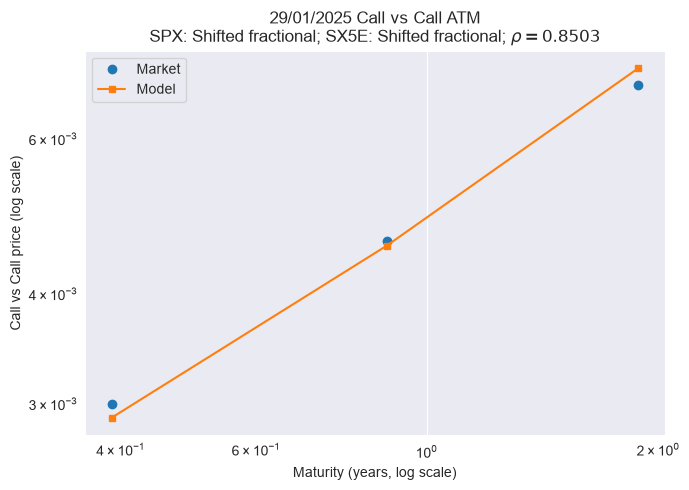

,maturity,market_cvc,calibration_grid_cvc,validation_grid_cvc,validation_absolute_error,validation_relative_error
0,0.389041,0.002999,0.002893,0.002893,-0.000107,-0.035564
1,0.887671,0.004594,0.004538,0.004538,-0.000055,-0.012080
2,1.884932,0.006915,0.007218,0.007218,0.000303,0.043876


,Asset,Parameter,Value,Status
0,SPX,H,0.143871,Fixed from ATM-skew calibration
1,SPX,eta,0.782245,Fixed from ATM-skew calibration
2,SPX,c,-0.999000,Fixed from ATM-skew calibration
3,SX5E,H,0.089245,Fixed from ATM-skew calibration
4,SX5E,eta,0.500000,Fixed from ATM-skew calibration
5,SX5E,c,-0.848936,Fixed from ATM-skew calibration
6,Joint model,rho,0.850285,Calibrated to CVC term structure


Calibration rule (N, Q): [(20, 30), (25, 30), (30, 30)]
Validation rule (N, Q): [(20, 30), (25, 30), (30, 30)]
Calibration-grid relative RMSE: 3.334591e-02
Validation absolute RMSE: 1.884199e-04
Validation relative RMSE: 3.334591e-02
Maximum calibration/validation price difference: 0.000000e+00
Maximum validation absolute error: 3.033969e-04
Maximum validation relative error: 4.387619e-02
Optimizer success: True


In [68]:
cvc_date = '20250129'
spx_kernel = 'shifted_fractional'
sx5e_kernel = 'shifted_fractional'

# These rho settings are local so this calibration can be edited independently.
initial_rho = CVC_INITIAL_RHO
lower_rho = CVC_LOWER_RHO
upper_rho = CVC_UPPER_RHO

result = calibrate_cvc_kernel_pair(
    cvc_date=cvc_date,
    spx_kernel=spx_kernel,
    sx5e_kernel=sx5e_kernel,
    initial_rho=initial_rho,
    lower_rho=lower_rho,
    upper_rho=upper_rho,
)
cvc_calibration_results[(cvc_date, spx_kernel, sx5e_kernel)] = result
display_cvc_calibration(result)

### SPX Two exponentials / SX5E Two exponentials

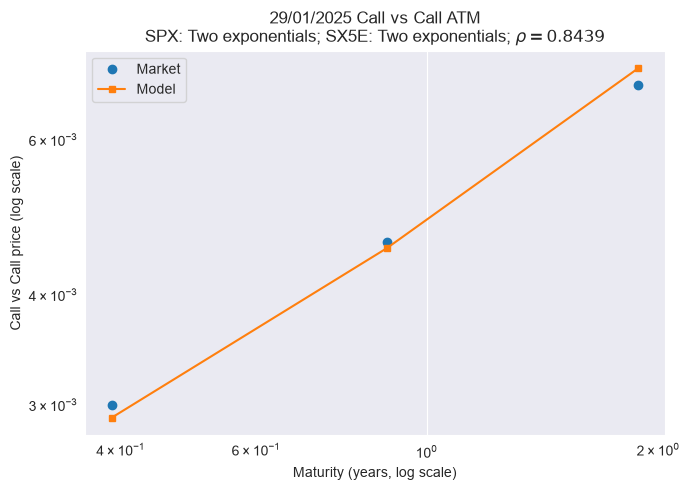

,maturity,market_cvc,calibration_grid_cvc,validation_grid_cvc,validation_absolute_error,validation_relative_error
0,0.389041,0.002999,0.002900,0.002900,-0.000100,-0.033228
1,0.887671,0.004594,0.004518,0.004518,-0.000076,-0.016484
2,1.884932,0.006915,0.007232,0.007232,0.000317,0.045848


,Asset,Parameter,Value,Status
0,SPX,kappa_1,0.657000,Fixed from ATM-skew calibration
1,SPX,kappa_2,24.900000,Fixed from ATM-skew calibration
2,SPX,a_1,0.456000,Fixed from ATM-skew calibration
3,SPX,eta,2.350000,Fixed from ATM-skew calibration
4,SPX,c,-0.999000,Fixed from ATM-skew calibration
5,SX5E,kappa_1,1.320000,Fixed from ATM-skew calibration
6,SX5E,kappa_2,32.400000,Fixed from ATM-skew calibration
7,SX5E,a_1,0.497000,Fixed from ATM-skew calibration
8,SX5E,eta,1.440000,Fixed from ATM-skew calibration
9,SX5E,c,-0.993000,Fixed from ATM-skew calibration


Calibration rule (N, Q): [(20, 30), (25, 30), (30, 30)]
Validation rule (N, Q): [(20, 30), (25, 30), (30, 30)]
Calibration-grid relative RMSE: 3.404822e-02
Validation absolute RMSE: 1.967856e-04
Validation relative RMSE: 3.404822e-02
Maximum calibration/validation price difference: 0.000000e+00
Maximum validation absolute error: 3.170303e-04
Maximum validation relative error: 4.584782e-02
Optimizer success: True


In [69]:
cvc_date = '20250129'
spx_kernel = 'two_exp'
sx5e_kernel = 'two_exp'

# These rho settings are local so this calibration can be edited independently.
initial_rho = CVC_INITIAL_RHO
lower_rho = CVC_LOWER_RHO
upper_rho = CVC_UPPER_RHO

result = calibrate_cvc_kernel_pair(
    cvc_date=cvc_date,
    spx_kernel=spx_kernel,
    sx5e_kernel=sx5e_kernel,
    initial_rho=initial_rho,
    lower_rho=lower_rho,
    upper_rho=upper_rho,
)
cvc_calibration_results[(cvc_date, spx_kernel, sx5e_kernel)] = result
display_cvc_calibration(result)


### Kernel-pair summary

In [61]:
display(cvc_summary('20250129', cvc_calibration_results))


,SPX kernel,SX5E kernel,rho,Validation absolute RMSE,Validation relative RMSE,Maximum validation relative error,Maximum grid price difference,Optimizer success
0,Shifted fractional,Shifted fractional,0.850285,0.000188,0.033346,0.043876,0.0,True
1,Two exponentials,Two exponentials,0.843861,0.000197,0.034048,0.045848,0.0,True


## 29/07/2025

### SPX Shifted fractional / SX5E Shifted fractional

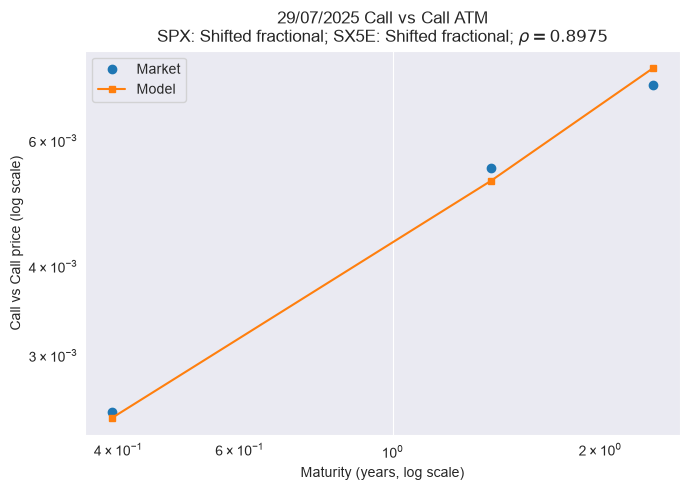

,maturity,market_cvc,calibration_grid_cvc,validation_grid_cvc,validation_absolute_error,validation_relative_error
0,0.391781,0.002499,0.002454,0.002454,-0.000046,-0.018367
1,1.389041,0.005495,0.005272,0.005272,-0.000223,-0.040656
2,2.386301,0.007173,0.007581,0.007581,0.000408,0.056913


,Asset,Parameter,Value,Status
0,SPX,H,0.105000,Fixed from ATM-skew calibration
1,SPX,eta,0.923000,Fixed from ATM-skew calibration
2,SPX,c,-0.999000,Fixed from ATM-skew calibration
3,SX5E,H,-0.116000,Fixed from ATM-skew calibration
4,SX5E,eta,0.493000,Fixed from ATM-skew calibration
5,SX5E,c,-0.999000,Fixed from ATM-skew calibration
6,Joint model,rho,0.897543,Calibrated to CVC term structure


Calibration rule (N, Q): [(20, 30), (30, 30), (30, 30)]
Validation rule (N, Q): [(20, 30), (30, 30), (30, 30)]
Calibration-grid relative RMSE: 4.175086e-02
Validation absolute RMSE: 2.699964e-04
Validation relative RMSE: 4.175086e-02
Maximum calibration/validation price difference: 0.000000e+00
Maximum validation absolute error: 4.082531e-04
Maximum validation relative error: 5.691335e-02
Optimizer success: True


In [70]:
cvc_date = '20250729'
spx_kernel = 'shifted_fractional'
sx5e_kernel = 'shifted_fractional'

# These rho settings are local so this calibration can be edited independently.
initial_rho = CVC_INITIAL_RHO
lower_rho = CVC_LOWER_RHO
upper_rho = CVC_UPPER_RHO

result = calibrate_cvc_kernel_pair(
    cvc_date=cvc_date,
    spx_kernel=spx_kernel,
    sx5e_kernel=sx5e_kernel,
    initial_rho=initial_rho,
    lower_rho=lower_rho,
    upper_rho=upper_rho,
)
cvc_calibration_results[(cvc_date, spx_kernel, sx5e_kernel)] = result
display_cvc_calibration(result)

### SPX Two exponentials / SX5E Two exponentials

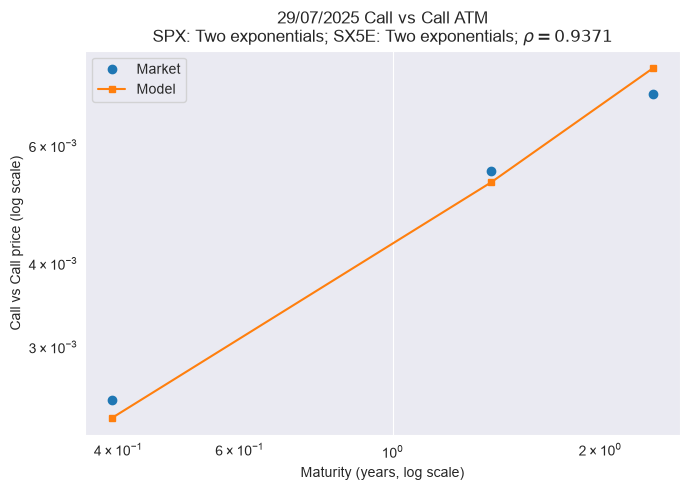

,maturity,market_cvc,calibration_grid_cvc,validation_grid_cvc,validation_absolute_error,validation_relative_error
0,0.391781,0.002499,0.002351,0.002351,-0.000148,-0.059352
1,1.389041,0.005495,0.005288,0.005288,-0.000207,-0.037660
2,2.386301,0.007173,0.007837,0.007837,0.000663,0.092487


,Asset,Parameter,Value,Status
0,SPX,kappa_1,0.454000,Fixed from ATM-skew calibration
1,SPX,kappa_2,20.000000,Fixed from ATM-skew calibration
2,SPX,a_1,0.376000,Fixed from ATM-skew calibration
3,SPX,eta,2.940000,Fixed from ATM-skew calibration
4,SPX,c,-0.999000,Fixed from ATM-skew calibration
5,SX5E,kappa_1,0.077900,Fixed from ATM-skew calibration
6,SX5E,kappa_2,20.300000,Fixed from ATM-skew calibration
7,SX5E,a_1,0.264000,Fixed from ATM-skew calibration
8,SX5E,eta,3.110000,Fixed from ATM-skew calibration
9,SX5E,c,-0.749000,Fixed from ATM-skew calibration


Calibration rule (N, Q): [(20, 30), (30, 30), (30, 30)]
Validation rule (N, Q): [(20, 30), (30, 30), (30, 30)]
Calibration-grid relative RMSE: 6.706933e-02
Validation absolute RMSE: 4.102770e-04
Validation relative RMSE: 6.706933e-02
Maximum calibration/validation price difference: 0.000000e+00
Maximum validation absolute error: 6.634344e-04
Maximum validation relative error: 9.248741e-02
Optimizer success: True


In [71]:
cvc_date = '20250729'
spx_kernel = 'two_exp'
sx5e_kernel = 'two_exp'

# These rho settings are local so this calibration can be edited independently.
initial_rho = CVC_INITIAL_RHO
lower_rho = CVC_LOWER_RHO
upper_rho = CVC_UPPER_RHO

result = calibrate_cvc_kernel_pair(
    cvc_date=cvc_date,
    spx_kernel=spx_kernel,
    sx5e_kernel=sx5e_kernel,
    initial_rho=initial_rho,
    lower_rho=lower_rho,
    upper_rho=upper_rho,
)
cvc_calibration_results[(cvc_date, spx_kernel, sx5e_kernel)] = result
display_cvc_calibration(result)


### Kernel-pair summary

In [64]:
display(cvc_summary('20250729', cvc_calibration_results))


,SPX kernel,SX5E kernel,rho,Validation absolute RMSE,Validation relative RMSE,Maximum validation relative error,Maximum grid price difference,Optimizer success
0,Shifted fractional,Shifted fractional,0.897543,0.00027,0.041751,0.056913,0.0,True
1,Two exponentials,Two exponentials,0.937093,0.00041,0.067069,0.092487,0.0,True


# Full calibration result

For each CVC date, the figure below gathers the two variance-swap
calibrations, the SPX and SX5E cross-kernel ATM-skew comparisons, and the
two retained Call vs Call calibrations. The marginal calibration date is
reported separately from the CVC date.


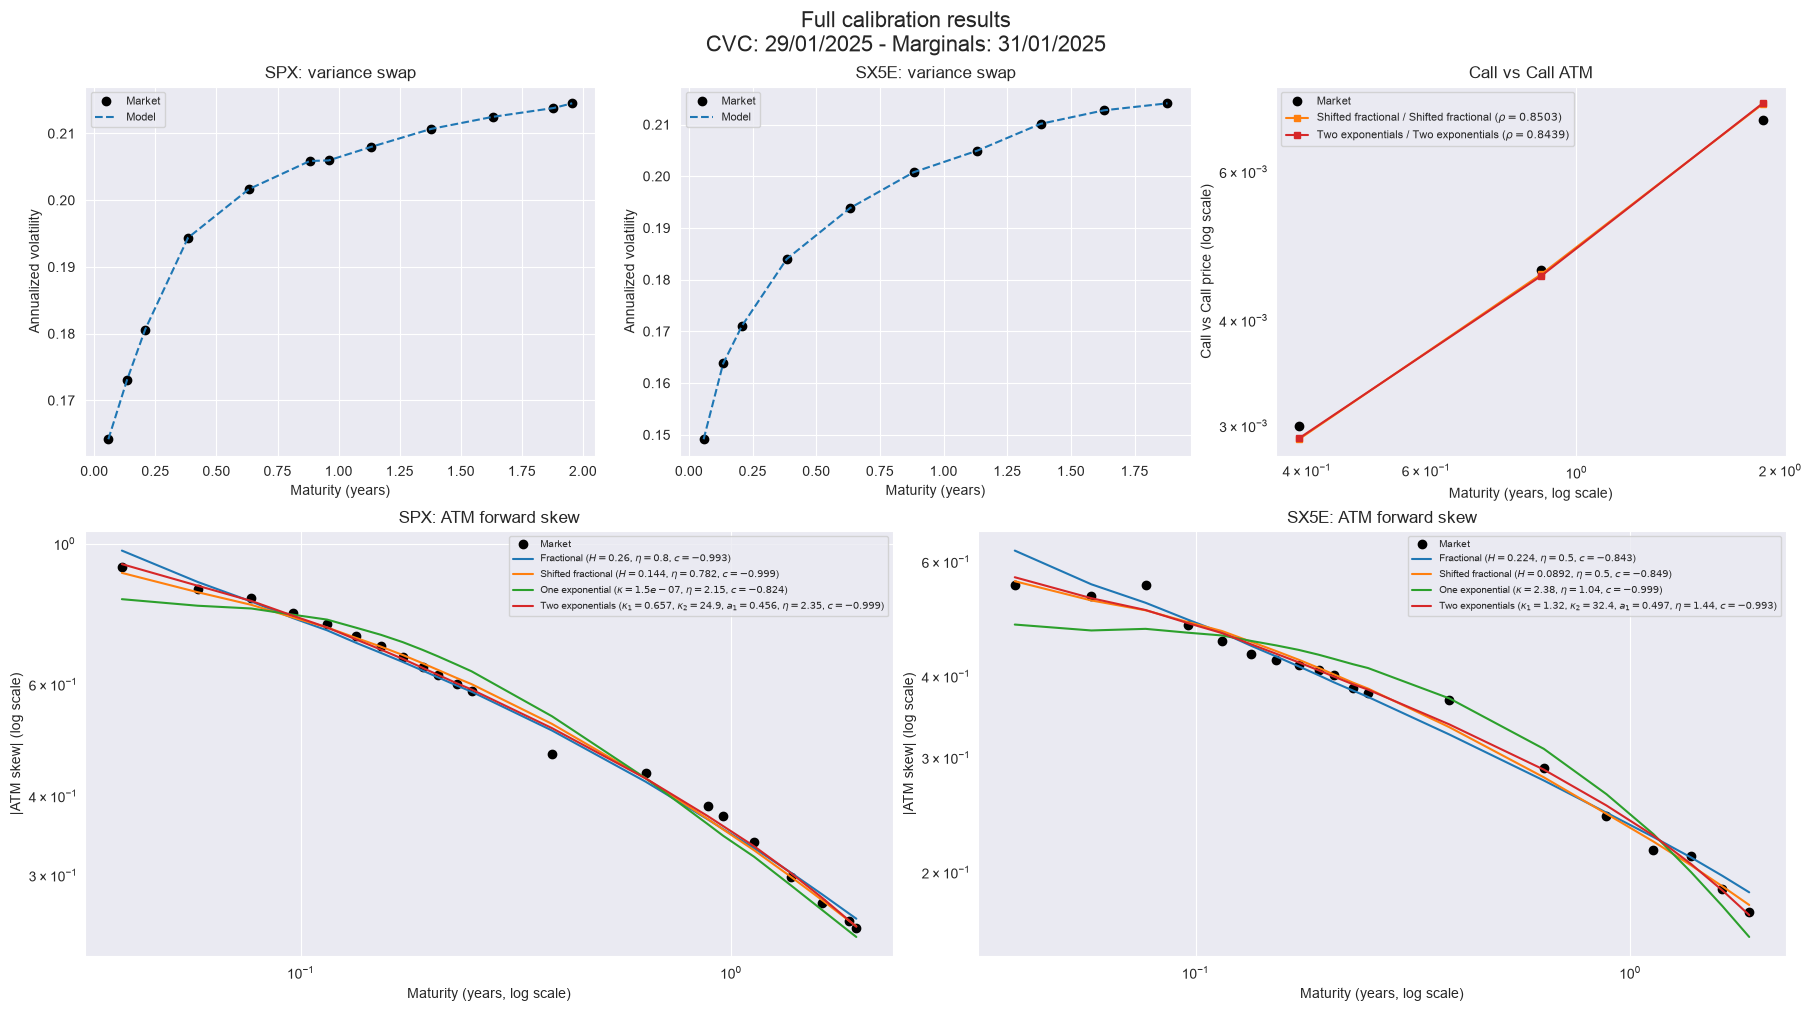

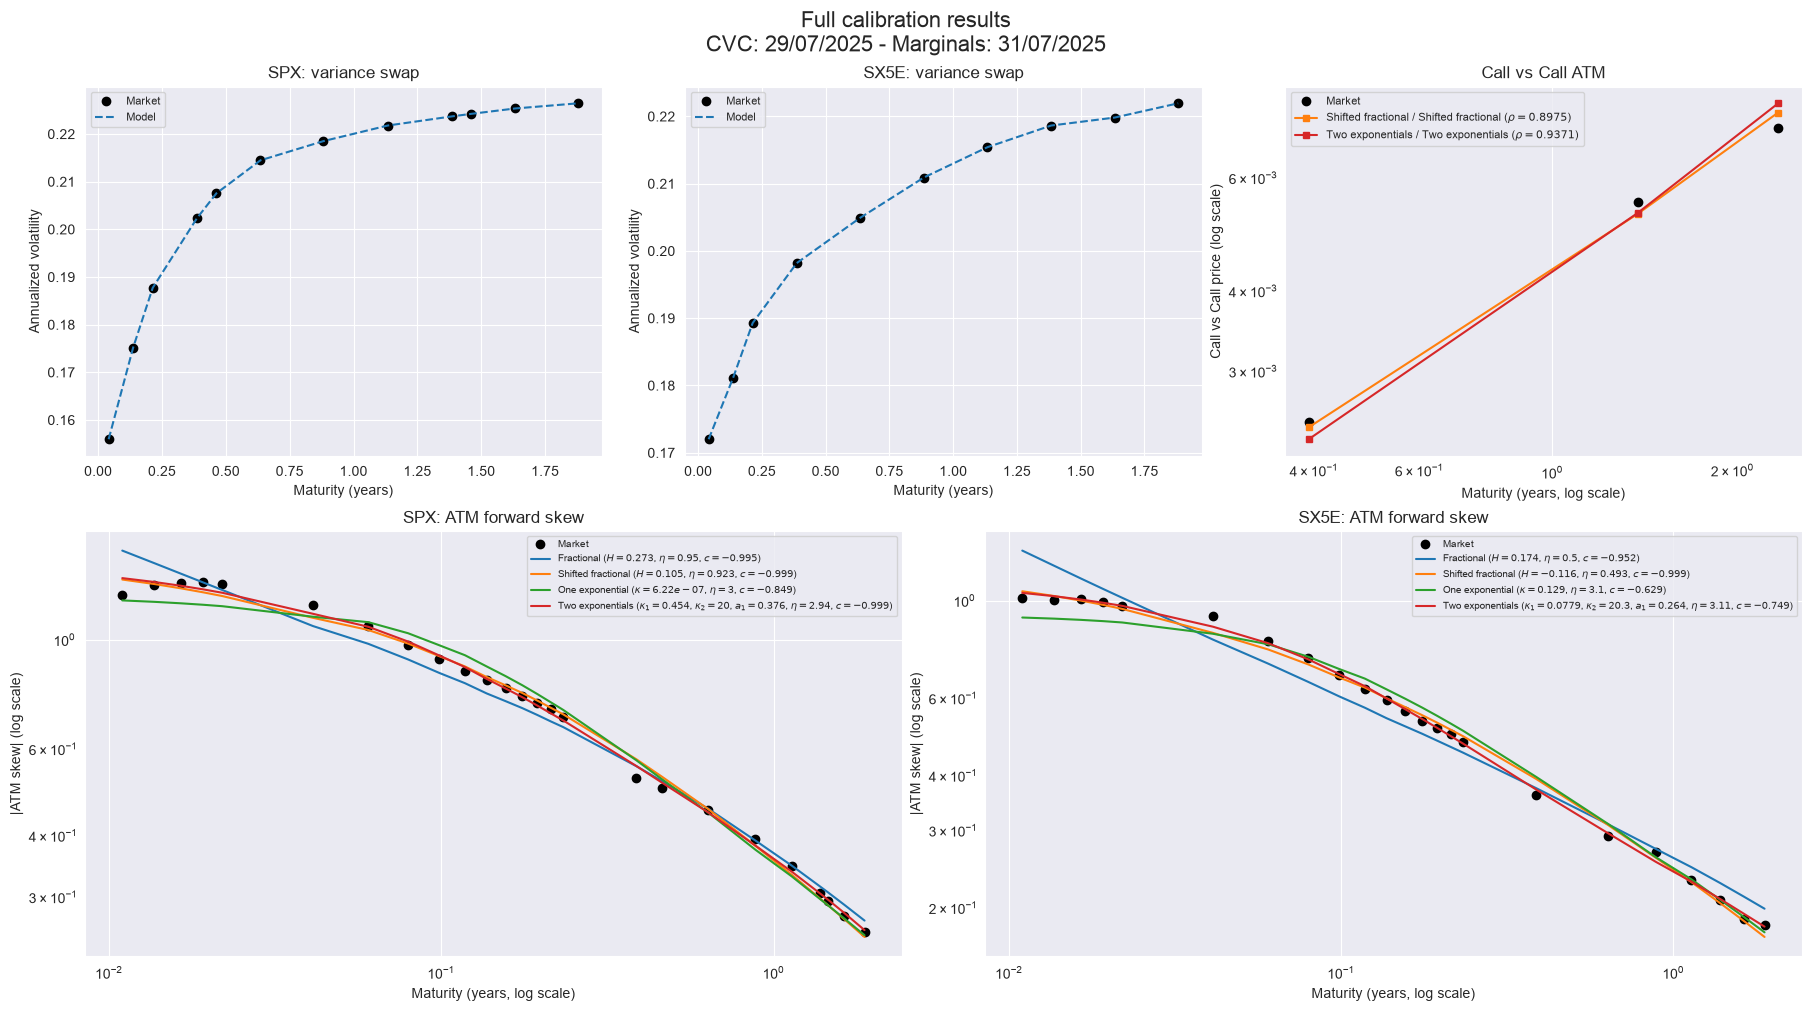

In [78]:
FULL_CALIBRATION_RESULTS_DIRECTORY = (
    PLOTS_DIRECTORY / 'Full calibration results'
)
FULL_CALIBRATION_RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)

FULL_CALIBRATION_PARAMETER_TEX = {
    'H': r'H',
    'kappa': r'\kappa',
    'eta': r'\eta',
    'c': r'c',
    'kappa_1': r'\kappa_1',
    'kappa_2': r'\kappa_2',
    'a_1': r'a_1',
}
FULL_CALIBRATION_CVC_CONFIGURATIONS = (
    ('shifted_fractional', 'Shifted fractional', 'tab:orange'),
    ('two_exp', 'Two exponentials', 'tab:red'),
)


def full_calibration_date_label(date):
    """Return an ISO-like YYYYMMDD string as DD/MM/YYYY."""

    return f'{date[6:8]}/{date[4:6]}/{date[:4]}'


def full_calibration_parameter_label(kernel_label, result):
    """Return one kernel label including its calibrated parameters."""

    parameters = ', '.join(
        f'${FULL_CALIBRATION_PARAMETER_TEX[name]}={value:.3g}$'
        for name, value in zip(
            result['parameter_names'], result['parameters']
        )
    )
    return f'{kernel_label} ({parameters})'


def plot_full_variance_swap_calibration(axis, dataset, asset_label):
    """Plot one market-versus-reconstructed variance-swap term structure."""

    comparison = g0_results[dataset]['comparison']
    axis.plot(
        comparison['maturity'], comparison['variance_swap_quote'],
        'o', color='black', label='Market',
    )
    axis.plot(
        comparison['maturity'],
        comparison['reconstructed_variance_swap_quote'],
        '--', color='tab:blue', label=r'Model',
    )
    axis.set_title(f'{asset_label}: variance swap')
    axis.set_xlabel('Maturity (years)')
    axis.set_ylabel('Annualized volatility')
    axis.grid(True)
    axis.legend(fontsize=8)


def plot_full_atm_skew_calibration(axis, dataset, asset_label):
    """Plot the four marginal ATM-skew calibrations on one axis."""

    market_result = kernel_results[0][1][dataset]
    axis.loglog(
        market_result['maturities'],
        np.abs(market_result['market_skews']),
        'o', color='black', label='Market',
    )
    for kernel_label, skew_results, color in kernel_results:
        result = skew_results[dataset]
        axis.loglog(
            result['maturities'],
            np.abs(result['model_skews']),
            '-', color=color,
            label=full_calibration_parameter_label(kernel_label, result),
        )
    axis.set_title(f'{asset_label}: ATM forward skew')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('|ATM skew| (log scale)')
    axis.grid(True)
    axis.legend(fontsize=7)


def plot_full_cvc_calibration(axis, cvc_date):
    """Plot the market and both retained CVC calibrations on one axis."""

    first_kernel = FULL_CALIBRATION_CVC_CONFIGURATIONS[0][0]
    first_result = cvc_calibration_results[(
        cvc_date, first_kernel, first_kernel
    )]
    axis.loglog(
        first_result['maturities'], first_result['market_quotes'],
        'o', color='black', label='Market',
    )
    for kernel_key, kernel_label, color in FULL_CALIBRATION_CVC_CONFIGURATIONS:
        result = cvc_calibration_results[(
            cvc_date, kernel_key, kernel_key
        )]
        axis.loglog(
            result['maturities'], result['model_quotes'],
            '-s', markersize=4, color=color,
            label=(
                f'{kernel_label} / {kernel_label} '
                rf'($\rho={result["rho"]:.4f}$)'
            ),
        )
    axis.set_title('Call vs Call ATM')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('Call vs Call price (log scale)')
    axis.grid(True)
    axis.legend(fontsize=8)


def plot_full_calibration_result(cvc_date):
    """Build, save and display the five-panel result for one CVC date."""

    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    spx_dataset = f'SPX_{marginal_date}'
    sx5e_dataset = f'SX5E_{marginal_date}'

    fig = plt.figure(figsize=(18, 10), constrained_layout=True)
    grid = fig.add_gridspec(2, 6, height_ratios=(1.0, 1.15))
    axes = {
        'spx_variance_swap': fig.add_subplot(grid[0, 0:2]),
        'sx5e_variance_swap': fig.add_subplot(grid[0, 2:4]),
        'cvc': fig.add_subplot(grid[0, 4:6]),
        'spx_atm_skew': fig.add_subplot(grid[1, 0:3]),
        'sx5e_atm_skew': fig.add_subplot(grid[1, 3:6]),
    }

    plot_full_variance_swap_calibration(
        axes['spx_variance_swap'], spx_dataset, 'SPX'
    )
    plot_full_variance_swap_calibration(
        axes['sx5e_variance_swap'], sx5e_dataset, 'SX5E'
    )
    plot_full_cvc_calibration(axes['cvc'], cvc_date)
    plot_full_atm_skew_calibration(
        axes['spx_atm_skew'], spx_dataset, 'SPX'
    )
    plot_full_atm_skew_calibration(
        axes['sx5e_atm_skew'], sx5e_dataset, 'SX5E'
    )

    fig.suptitle(
        'Full calibration results\n'
        f'CVC: {full_calibration_date_label(cvc_date)} - '
        f'Marginals: {full_calibration_date_label(marginal_date)}',
        fontsize=16,
    )
    fig.savefig(
        FULL_CALIBRATION_RESULTS_DIRECTORY
        / f'full_calibration_results_{cvc_date}.png',
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()
    return fig


full_calibration_figures = {}
for cvc_date in ('20250129', '20250729'):
    full_calibration_figures[cvc_date] = plot_full_calibration_result(
        cvc_date
    )
